# 32 – Modellvergleich: welches Modell für welche Aufgabe?

**Zweck:** Im Projekt sind rund dreißig Notebooks entstanden, fast jedes mit einem eigenen
Modell oder einer eigenen Regel, und fast jedes hat sich **selbst** geprüft: mit eigenem
Zeitraum, eigenen Stationen, eigener Kontrollgruppe und eigener Alarmmenge. Deshalb lässt
sich bisher nicht sagen, welches Modell für welche Aufgabe das beste ist. Dieses Notebook
stellt die Kandidaten **nebeneinander auf denselben Prüfstand** (`src/pruefstand.py`):
gleiche Fälle, gleiche Stationen und Tage, gleiche Alarmmenge, gleiche Kennzahlen.

**Was am Ende herauskommen soll** (Folie 5 des Projektpartners und Aufgabenstellung):

| Aufgabe | Frage | Prüfstein | Kandidaten |
|---|---|---|---|
| **A · Alarm** (Anomalieerkennung) | Meldet der Wächter, dass sich eine Station verändert? | Begehungen als echte Veränderungen; eingerechnete Fehler mit bekanntem Beginn; der Ventilfall 68956351 | Normalverhaltensmodell (NB 17), Tagesmonitor (`src/tagesmonitor.py`), Prognose-LSTM (NB 21) mit zwei Alarmregeln, Wochenmittel ohne Lernen |
| **B · Fehler erkennen** | Welche Station hat einen Dauerfehler (Ventil, Dämmung, zu großer Anschluss)? | Befunde der Begehungen, nur Daten **vor** der Begehung; Gegenprobe im Winter danach | Regelwerk aus dem README, Kennzahl-Regeln, K-Means (NB 19), Netzvergleich (Kennlinien-Strang), Normkennzahl (NB 17), logistische Regression, LSTM-Embedding (NB 20/22) |
| **C · Fehler unterteilen und empfehlen** | Welche Handlung je Station: Reparatur, Regelungsoptimierung, Kapazitätsanpassung? | Treffer der Klasse gegen den Befund; Übereinstimmung der Einteilungen | Klassen nach Folie 5 (NB 22, als Paket), Fehlerbild des Netzvergleichs, Regelwerk |

**Voraussetzungen:** Notebook 00, 06, 17, 18, 20, 21 und 22 sind gelaufen (ihre Ausgaben liegen in
`data/processed/` und `notebooks/models/`). Die Modellpakete unter `models/` werden hier gebaut, falls
sie fehlen (`src/modellpaket.py`).

**Ergebnis:** Tabellen in `outputs/pruefstand/`, zusammengefasst in `docs/modellvergleich.md`.

## Die Spielregeln eines fairen Vergleichs

Jede dieser Regeln stammt aus einem Fehler, der im Projekt schon einmal passiert ist.

| Regel | Warum | Wo es schiefging |
|---|---|---|
| 1. **Eine Frage je Aufgabe, vorher festgelegt** | Wer die Frage nach dem Ergebnis wählt, findet immer einen Sieger | „Maßnahme ja/nein“ als Label (76 % ja) trennte nichts (NB 01, 04, ML-Klassifikator) |
| 2. **Derselbe Prüfstein** | Begehungen, eingerechnete Fehler und Labels messen Verschiedenes | „70 % gegen 53 %“ (NB 17) und „11–17 % gegen 13 %“ (NB 21) waren nicht vergleichbar (NB 23) |
| 3. **Dieselben Stationen und Tage** | Ein Modell, das nur die einfachen Tage sieht, sieht besser aus | NB 17 rechnet nur Heiztage, NB 21 alle Tage |
| 4. **Dieselbe Alarmmenge bzw. Fehlalarmquote** | Wer öfter alarmiert, trifft automatisch öfter | erste Fassung von NB 21 |
| 5. **Nur ungesehene Daten** | Ein Modell, das die Prüftage gelernt hat, misst sich selbst | alte LSTM-Gewichte nach geänderter Datenbasis (CHANGELOG, 24.10.) |
| 6. **Unsicherheit angeben, gepaart vergleichen** | Bei 11 Ventilfällen streut die AUC um ±0,15 | vertauschte Labels erreichen AUC 0,27 bis 0,73 (NB 22) |
| 7. **Bei Gleichstand gewinnt das Einfachere** | Eine Regel ist erklärbar, braucht kein Training und bricht nicht still | Sommernacht-Regel 0,85 gegen LSTM 0,89, nicht unterscheidbar (NB 22) |

**Regeln sind Kandidaten wie Modelle.** Eine Regel ist ein Modell ohne Lernen: Sie liefert für jede
Station einen Wert (z. B. den Anteil der Sommernächte mit Durchfluss) oder für jeden Tag einen Alarm.
Damit läuft sie durch genau dieselbe Prüfung. „Nebeneinanderschalten“ heißt hier: Jeder Kandidat
liefert dieselbe Art Ausgabe, und der Prüfstand bewertet alle Ausgaben gleich.

## 1 · Setup

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import fault_detection as fd
from src import fehlerklassen as fk
from src import modellpaket as mp
from src import normalmodell_waechter as nw
from src import prognose_waechter as pw
from src import pruefstand as ps
from src import regelkalibrierung as rk
from src import stationsblatt as sbl
from src import tagesmonitor as tm
from src.features import features_for_meter
from src.load_begehungen import begehungen_mit_zaehler

PROCESSED = ROOT / "data" / "processed"
AUSGABE = ROOT / "outputs" / "pruefstand"
AUSGABE.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True})
# Farben in geprüfter Reihenfolge (farbenblind-tauglich): eine Farbe je Kandidat, nie nach Rang
FARBE = {"blau": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "gelb": "#eda100",
         "magenta": "#e87ba4", "gruen": "#008300", "violett": "#6250d6", "rot": "#e34948", "grau": "#898781"}
AB = pd.Timestamp("2024-06-01")      # ab hier überwacht das LSTM (vorher hat es gelernt)
t_start = time.time()

**Was macht diese Zelle?**
- Lädt die Module des Prüfstands und der Modellpakete. Alle Prüfungen stehen in `src/pruefstand.py`,
  damit sie für jeden Kandidaten **identisch** laufen und getestet sind (`tests/test_pruefstand.py`).
- `AB`: Das Prognose-LSTM hat bis Ende Mai 2024 gelernt. Verglichen wird erst ab Juni 2024 (Regel 5).

In [2]:
def paket_da(name):
    return mp.aktuelle_version(name) is not None

stunden = pd.read_parquet(PROCESSED / "modell_stunden.parquet")
labels = pd.read_csv(PROCESSED / "modell_labels.csv", index_col="zaehler", parse_dates=["erste_begehung"])
for name, bauen in (("prognose_lstm", pw.paket_bauen), ("normalmodell", nw.paket_bauen), ("fehlerklassen", fk.paket_bauen)):
    if not paket_da(name):
        print(f"{name}: kein Paket, wird gebaut ...")
        bauen()
mp.uebersicht().query("aktuell")[["name", "version", "aufgabe", "datenstand", "commit"]]

,name,version,aufgabe,datenstand,commit
0,fehlerklassen,2026-10-24_132610,Fehler erkennen und unterteilen (Folie 5),2026-07-20T11:00:00,cf384a72
1,normalmodell,2026-10-24_132558,Alarm (Wächter),2026-06-12T00:00:00,cf384a72
2,prognose_lstm,2026-10-24_132552,Alarm (Wächter),2026-07-20T11:00:00,cf384a72


**Was macht diese Zelle?**
- Prüft, ob die drei Modellpakete gebaut sind, und baut sie sonst aus den Ausgaben der Notebooks.
- Ein **Modellpaket** enthält alles, was ein Modell zum Anwenden braucht: Gewichte, Skalierung,
  Kalibrierung, Schwelle, Datenstand und Code-Stand (`src/modellpaket.py`). Die Tabelle zeigt, welche
  Version gerade gilt. Jedes Paket wurde beim Bauen gegen seine Notebook-Ausgabe geprüft
  (`python -m src.prognose_waechter --gegenprobe`, `python -m src.fehlerklassen --gegenprobe`).

## 2 · Teil A: Alarm – welcher Wächter meldet Veränderungen?

### Die Kandidaten

Jeder Wächter besteht aus zwei Teilen, die sich **getrennt austauschen** lassen:

1. einer **Erwartung**: was die Station heute tun sollte,
2. einer **Alarmregel**: wann die Abweichung von der Erwartung ein Alarm ist.

| Kandidat | Erwartung | Alarmregel | Daten |
|---|---|---|---|
| **Normalverhaltensmodell** (NB 17, Seb) | Kennlinie je Station gegen die Tagesmitteltemperatur, gelernt im ersten Jahr | CUSUM, h = 5 | Tageswerte aus Zählerständen, nur Heiztage |
| **Tagesmonitor** (`src/tagesmonitor.py`, Kennlinien-Strang) | dieselbe Idee auf den NB-00-Reihen, als Paket `normalmodell` | CUSUM | wie oben |
| **Prognose-LSTM, Schwelle** (NB 21) | Netz: 7 Vortage, Wetter, Vorlauf → Tagesverlauf | \|z\| ≥ Schwelle an zwei Tagen | Stundenwerte, alle Tage |
| **Prognose-LSTM, CUSUM** (neu) | dasselbe Netz | CUSUM auf denselben z-Werten | wie oben |
| **Wochenmittel, Schwelle** (ohne Lernen) | jede Stunde = Mittel derselben Stunde der 7 Vortage | wie NB 21 | wie oben |
| **Wochenmittel, CUSUM** (ohne Lernen) | wie oben | CUSUM | wie oben |

Notebook 23 hat vermutet, dass der Abstand zwischen Normalverhaltensmodell und LSTM an der
**Alarmregel** liegt und nicht am Netz. Mit den Kombinationen lässt sich das jetzt prüfen.

Die übrigen Wächter des Projekts (Notebook 10, 14, 24 und `arima`) folgen im Abschnitt „Weitere Wächter aus dem
Projekt“, auf denselben Tagen und mit denselben Fällen.

Die übrigen Wächter des Projekts (Notebook 10, 14, 24 und `arima`) folgen im Abschnitt „Weitere Wächter aus dem
Projekt“, auf denselben Tagen und mit denselben Fällen.

In [3]:
# Begehungen: Termine je Zähler (Kontrollregel) und die Fälle, die NB 17 bewertet hat
mit_tageswerten = set(pd.read_csv(PROCESSED / "hast_tage.csv", usecols=["zaehler"])["zaehler"])
beg = begehungen_mit_zaehler(available=mit_tageswerten).dropna(subset=["meter", "datum"])
termine = {int(z): sorted(set(g["datum"])) for z, g in beg.groupby("meter")}
seb_treffer = pd.read_csv(PROCESSED / "normalmodell_treffer.csv", parse_dates=["datum"])
faelle = seb_treffer.drop_duplicates(["zaehler", "datum"])[["zaehler", "datum", "mechanisch"]].reset_index(drop=True)

# Kandidat 1: Normalverhaltensmodell aus NB 17
seb_alarme = pd.read_csv(PROCESSED / "normalmodell_alarme.csv", parse_dates=["datum"])
seb_tage = pd.read_csv(PROCESSED / "normalmodell_tage.csv", parse_dates=["datum"])
seb_beob = seb_tage[~seb_tage["referenz"] & (seb_tage["kanal"] == "kwh_pro_m3")][["zaehler", "datum"]]

# Kandidat 2: Tagesmonitor als Paket
e = nw.eingaben()
normal = nw.anwenden(nw.lade(), e["serien"], e["temp"])
tm_verlauf = normal["verlauf"].rename(columns={"meter": "zaehler"})
tm_beob = tm_verlauf[tm_verlauf["kanal"] == "kwh_pro_m3"][["zaehler", "datum"]]

# Kandidaten 3 bis 6: Prognose-LSTM und Wochenmittel auf denselben Tagen
lstm_paket = pw.lade()
r = pw.nachrechnen(stunden, labels)               # Abschnitte (Training, Validierung, ...) wie NB 21
ziel = r["abweichungen"].index.to_numpy()
rl_w, fl_w = pw.wochenmittel(r["werte"], ziel)
abw_w = pw.abweichungen(r["werte"], r["tage"], ziel, rl_w, fl_w)
abw_w["abschnitt"] = r["abweichungen"]["abschnitt"].to_numpy()
kal_w, faktor_w = pw.kalibrieren(abw_w[abw_w["abschnitt"] == "Validierung"])

lstm = pw.anwenden(lstm_paket, stunden)
lstm = lstm[lstm["status"] == "überwacht"]
woche = pw.anwenden(lstm_paket, stunden, erwartung="wochenmittel", kalibrierung=kal_w, faktor=faktor_w)
woche = woche[woche["status"] == "überwacht"]
lstm_beob = lstm[["zaehler", "tag"]].rename(columns={"tag": "datum"})

pd.DataFrame({
    "Stationen": [seb_beob["zaehler"].nunique(), tm_beob["zaehler"].nunique(), lstm["zaehler"].nunique(), woche["zaehler"].nunique()],
    "überwachte Tage": [len(seb_beob), len(tm_beob), len(lstm), len(woche)],
}, index=["Normalverhaltensmodell (NB 17)", "Tagesmonitor (Paket)", "Prognose-LSTM (Paket)", "Wochenmittel"])

,Stationen,überwachte Tage
Normalverhaltensmodell (NB 17),89,34808
Tagesmonitor (Paket),89,35707
Prognose-LSTM (Paket),87,58524
Wochenmittel,87,58524


**Was macht diese Zelle?**
- Liest die Begehungstermine wie Notebook 17 und 23 und übernimmt **dieselben Fälle**, die Notebook 17
  bewertet hat (Termine an überwachten Stationen nach dem Ende ihrer Referenz).
- Lädt die Ausgaben aller Kandidaten. Tagesmonitor und Prognose-LSTM kommen aus ihren **Modellpaketen**,
  also genau so, wie sie im Betrieb laufen würden.
- Für das Wochenmittel wird die normale Schwankung je Station aus denselben Validierungstagen bestimmt
  wie beim LSTM. Sonst hätte es einen Nachteil, der nichts mit der Erwartung zu tun hat.

In [4]:
def schwellen_alarme(tab):
    def f(s):
        w = pw.warnungen(tab, s)
        return tab.loc[pw.alarme_aus_warnungen(tab, w), ["zaehler", "tag"]].rename(columns={"tag": "datum"})
    return f


def cusum_alarme(tab, kal):
    def f(h):
        c = pw.cusum_alarme(tab, kal, h=h)
        return tab.loc[c["cusum_alarm"].to_numpy(), ["zaehler", "tag"]].rename(columns={"tag": "datum"})
    return f


def tagesmonitor_alarme(h):
    zeilen = []
    for (z, kanal), g in tm_verlauf.groupby(["zaehler", "kanal"]):
        g = g.sort_values("datum")
        _, _, al = tm.cusum(g["z"].to_numpy(), h=h, deckel=max(tm.CUSUM_MAX, 2 * h))
        zeilen += [(z, g["datum"].iloc[i]) for i, _, _ in al]
    return pd.DataFrame(zeilen, columns=["zaehler", "datum"])


gemeinsam = ps.gemeinsame_tage(seb_beob, tm_beob, lstm_beob, ab=AB)
budget = len(ps.auf_tagen(seb_alarme, gemeinsam))
print(f"Gemeinsame Grundlage: {gemeinsam['zaehler'].nunique()} Stationen, {len(gemeinsam):,} Stationstage "
      f"({gemeinsam['datum'].min():%d.%m.%Y} bis {gemeinsam['datum'].max():%d.%m.%Y})")
print(f"Alarmbudget: {budget} Alarme des Normalverhaltensmodells auf diesen Tagen")

suche = {
    "Tagesmonitor": (tagesmonitor_alarme, [4, 4.5, 5, 5.5, 6]),
    "Prognose-LSTM, Schwelle": (schwellen_alarme(lstm), [3, 3.5, 4, 4.5, 5, 6]),
    "Prognose-LSTM, CUSUM": (cusum_alarme(lstm, lstm_paket["kalibrierung"]), [6, 7, 8, 8.5, 9, 9.5, 10, 11, 12]),
    "Wochenmittel, Schwelle": (schwellen_alarme(woche), [2, 2.5, 3, 3.5, 4, 4.5, 5, 6, 7, 8]),
    "Wochenmittel, CUSUM": (cusum_alarme(woche, kal_w), [6, 8, 10, 12, 14, 16, 18, 20]),
}
parameter, budget_tafeln = {}, []
for name, (funktion, werte) in suche.items():
    parameter[name], tafel = ps.budget_anpassen(funktion, werte, budget, gemeinsam)
    budget_tafeln.append(tafel.assign(Kandidat=name))
budget_tab = pd.concat(budget_tafeln).pivot_table(index="wert", columns="Kandidat", values="alarme")
print("Gewählt (Alarmmenge am nächsten am Budget):", {k: v for k, v in parameter.items()})
budget_tab

Gemeinsame Grundlage: 79 Stationen, 15,142 Stationstage (01.06.2024 bis 09.06.2025)
Alarmbudget: 204 Alarme des Normalverhaltensmodells auf diesen Tagen


Gewählt (Alarmmenge am nächsten am Budget): {'Tagesmonitor': 4.5, 'Prognose-LSTM, Schwelle': 3.5, 'Prognose-LSTM, CUSUM': 8.0, 'Wochenmittel, Schwelle': 3.0, 'Wochenmittel, CUSUM': 12.0}


Kandidat,"Prognose-LSTM, CUSUM","Prognose-LSTM, Schwelle",Tagesmonitor,"Wochenmittel, CUSUM","Wochenmittel, Schwelle"
wert,,,,,
2.0,NaN,NaN,NaN,NaN,415.0
2.5,NaN,NaN,NaN,NaN,315.0
3.0,NaN,237.0,NaN,NaN,217.0
3.5,NaN,192.0,NaN,NaN,171.0
4.0,NaN,147.0,223.0,NaN,144.0
4.5,NaN,120.0,208.0,NaN,120.0
5.0,NaN,100.0,198.0,NaN,104.0
5.5,NaN,NaN,187.0,NaN,NaN
6.0,316.0,68.0,180.0,464.0,88.0


**Was macht diese Zelle?**
- Bildet die **gemeinsame Grundlage**: Stationen und Tage, die alle Wächter überwachen. Das sind Heiztage
  ab Juni 2024, weil das Normalverhaltensmodell nur Heiztage rechnet (Regel 3).
- Das **Alarmbudget** ist die Zahl der Alarme des Normalverhaltensmodells auf diesen Tagen.
- Für jeden anderen Kandidaten wird sein Parameter (Schwelle bzw. CUSUM-Grenze h) so gewählt, dass er
  **gleich viele Alarme** gibt (Regel 4). Die Tabelle zeigt die Alarmmenge je Parameter.
- Hinweis zum CUSUM: Die Konten werden bei mindestens 2 h gedeckelt, sonst wäre ein h ≥ 10 nie
  erreichbar.

In [5]:
kandidaten_a = {
    "Normalverhaltensmodell (NB 17)": seb_alarme[["zaehler", "datum"]],
    "Tagesmonitor": tagesmonitor_alarme(parameter["Tagesmonitor"]),
    "Prognose-LSTM, Schwelle": schwellen_alarme(lstm)(parameter["Prognose-LSTM, Schwelle"]),
    "Prognose-LSTM, CUSUM": cusum_alarme(lstm, lstm_paket["kalibrierung"])(parameter["Prognose-LSTM, CUSUM"]),
    "Wochenmittel, Schwelle": schwellen_alarme(woche)(parameter["Wochenmittel, Schwelle"]),
    "Wochenmittel, CUSUM": cusum_alarme(woche, kal_w)(parameter["Wochenmittel, CUSUM"]),
}
zeilen, treffer_je_fall = [], {}
for nach in (60, 14):
    for name, alarme in kandidaten_a.items():
        a = ps.auf_tagen(alarme, gemeinsam)
        t = ps.trefferpruefung(a, gemeinsam, faelle, termine, nach=nach)
        treffer_je_fall[(name, nach)] = t.set_index(["zaehler", "datum"])["treffer"]
        zeilen.append({"Fenster": f"−7 bis +{nach} Tage", "Alarme": len(a), **ps.bilanz(t, name)})
alarm_tab = pd.DataFrame(zeilen)
alarm_tab.round(3)

,Fenster,Alarme,Kandidat,Fälle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,−7 bis +60 Tage,204,Normalverhaltensmodell (NB 17),43,30,0.698,0.503,1.387,0.008
1,−7 bis +60 Tage,208,Tagesmonitor,43,33,0.767,0.529,1.452,0.001
2,−7 bis +60 Tage,192,"Prognose-LSTM, Schwelle",43,16,0.372,0.315,1.181,0.257
3,−7 bis +60 Tage,204,"Prognose-LSTM, CUSUM",43,24,0.558,0.395,1.415,0.022
4,−7 bis +60 Tage,217,"Wochenmittel, Schwelle",43,24,0.558,0.357,1.563,0.006
5,−7 bis +60 Tage,182,"Wochenmittel, CUSUM",43,16,0.372,0.195,1.905,0.005
6,−7 bis +14 Tage,204,Normalverhaltensmodell (NB 17),39,14,0.359,0.219,1.636,0.033
7,−7 bis +14 Tage,208,Tagesmonitor,39,18,0.462,0.244,1.888,0.003
8,−7 bis +14 Tage,192,"Prognose-LSTM, Schwelle",39,7,0.179,0.173,1.038,0.523
9,−7 bis +14 Tage,204,"Prognose-LSTM, CUSUM",39,8,0.205,0.135,1.520,0.147


**Was macht diese Zelle?**
- Berechnet die Alarme jedes Kandidaten mit dem Parameter für das gleiche Budget und behält nur Alarme
  auf den gemeinsamen Tagen.
- Prüft alle mit **derselben Funktion** `ps.trefferpruefung` (Sebs Verfahren aus NB 17, Abschnitt 11,
  Fall für Fall nachgeprüft): Hat die begangene Station im Fenster einen Alarm? Wie oft alarmieren
  Kontrollstationen im selben Fenster? **Hebel** = Quote / Kontrollquote, p aus dem Binomialtest.
- Zweimal: mit 60 Tagen nach der Begehung (wie NB 17) und mit 14 Tagen (schnelle Reaktion).

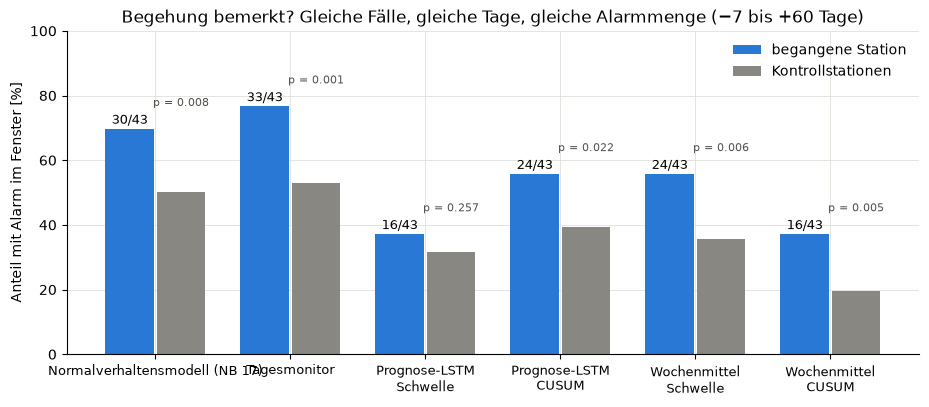

,nur Normalverhaltensmodell,nur Kandidat,beide,keiner,p (McNemar)
Tagesmonitor,0.0,3.0,30.0,10.0,0.250
"Prognose-LSTM, Schwelle",15.0,1.0,15.0,12.0,0.001
"Prognose-LSTM, CUSUM",12.0,6.0,18.0,7.0,0.238
"Wochenmittel, Schwelle",11.0,5.0,19.0,8.0,0.210
"Wochenmittel, CUSUM",16.0,2.0,14.0,11.0,0.001


In [6]:
lange = alarm_tab[alarm_tab["Fenster"] == "−7 bis +60 Tage"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(lange))
ax.bar(x - 0.19, lange["Quote"] * 100, 0.36, color=FARBE["blau"], label="begangene Station")
ax.bar(x + 0.19, lange["Kontrollquote"] * 100, 0.36, color=FARBE["grau"], label="Kontrollstationen")
for xi, zeile in lange.iterrows():
    ax.text(xi - 0.19, zeile["Quote"] * 100 + 1.5, f"{zeile['Treffer']}/{zeile['Fälle']}", ha="center", fontsize=9)
    ax.text(xi + 0.19, max(zeile["Quote"], zeile["Kontrollquote"]) * 100 + 7, f"p = {zeile['p (einseitig)']:.3f}",
            ha="center", fontsize=8, color="#52514e")
ax.set_xticks(x, lange["Kandidat"].str.replace(", ", "\n"), fontsize=9)
ax.set_ylabel("Anteil mit Alarm im Fenster [%]")
ax.set_ylim(0, 100)
ax.set_title("Begehung bemerkt? Gleiche Fälle, gleiche Tage, gleiche Alarmmenge (−7 bis +60 Tage)")
ax.legend(frameon=False, loc="upper right")
plt.show()

bezug = treffer_je_fall[("Normalverhaltensmodell (NB 17)", 60)]
paarweise = pd.DataFrame({name: ps.mcnemar(bezug, treffer_je_fall[(name, 60)].reindex(bezug.index))
                          for name in kandidaten_a if not name.startswith("Normal")}).T
paarweise.rename(columns={"nur A": "nur Normalverhaltensmodell", "nur B": "nur Kandidat"}).round(3)

**Was machen die beiden Teile?**
- Das Bild stellt je Wächter die Trefferquote an den begangenen Stationen (blau) neben die der
  Kontrollstationen (grau). Entscheidend ist der **Abstand** zwischen beiden, nicht die Höhe.
- Die Tabelle vergleicht jeden Kandidaten **Fall für Fall** mit dem Normalverhaltensmodell: In wie vielen
  Fällen alarmiert nur der eine, nur der andere? Der McNemar-Test schaut nur auf diese uneinigen Fälle.

**Ergebnis**

Gemeinsame Grundlage: 79 Stationen, 15.142 Heiztage vom 01.06.2024 bis 09.06.2025, dieselben 43 Begehungen,
Budget 204 Alarme.

| Kandidat | Parameter | bemerkt (−7 bis +60 Tage) | Kontrolle | Hebel | p | in 14 Tagen | p |
|---|---|---|---|---|---|---|---|
| **Tagesmonitor** | h = 4,5 | **33/43 (77 %)** | 53 % | 1,45 | **0,001** | 18/39 (46 %) gegen 24 % | **0,003** |
| Normalverhaltensmodell (NB 17) | h = 5 | 30/43 (70 %) | 50 % | 1,39 | 0,008 | 14/39 (36 %) gegen 22 % | 0,033 |
| Prognose-LSTM, CUSUM | h = 8 | 24/43 (56 %) | 40 % | 1,42 | 0,022 | 8/39 (21 %) gegen 14 % | 0,15 |
| Wochenmittel, Schwelle | z ≥ 3 | 24/43 (56 %) | 36 % | 1,56 | 0,006 | 14/39 (36 %) gegen 17 % | 0,003 |
| Wochenmittel, CUSUM | h = 12 | 16/43 (37 %) | 20 % | 1,91 | 0,005 | 7/39 (18 %) gegen 11 % | 0,13 |
| Prognose-LSTM, Schwelle | z ≥ 3,5 | 16/43 (37 %) | 32 % | 1,18 | 0,26 | 7/39 (18 %) gegen 17 % | 0,52 |

- **Die Kennlinie gegen die Außentemperatur bleibt der beste Wächter für Begehungen.** Tagesmonitor und
  Normalverhaltensmodell sind dieselbe Idee in zwei Umsetzungen und Fall für Fall nicht unterscheidbar
  (Tagesmonitor 3 Fälle mehr, keiner weniger, McNemar p = 0,25). Für den Betrieb nehmen wir den
  Tagesmonitor, weil er als Paket auf neuen Daten läuft.
- **Die Vermutung aus Notebook 23 stimmt zur Hälfte.** Dieselben LSTM-z-Werte mit CUSUM statt Schwelle
  bemerken 24 statt 16 Begehungen und sind damit belegt (p = 0,022). Die Alarmregel macht also einen
  großen Teil aus. Zur Kennlinie fehlen aber weiter 6 bis 9 Fälle: Das LSTM nimmt die letzten sieben Tage
  als Eingang, eine bleibende Veränderung wird so nach einer Woche Teil seiner Erwartung.
- **Ohne Lernen geht es besser als mit dem LSTM-Wächter von NB 21:** Das Wochenmittel mit Schwellenregel
  bemerkt 24 Begehungen, auch schon in 14 Tagen (p = 0,003). Das LSTM sagt die Station zu gut voraus, auch
  wenn sie sich gerade verändert.
- Fall für Fall liegt das Normalverhaltensmodell nur gegen „LSTM, Schwelle“ und „Wochenmittel, CUSUM“
  belegt vorn (je p = 0,001), gegen die übrigen nicht.

### Weitere Wächter aus dem Projekt

Dieselbe Prüfung für alle übrigen Ansätze, die je Station und Tag einen Alarm liefern können:

| Kandidat | Notebook | Erwartung | Alarmregel |
|---|---|---|---|
| **Kennlinienmonitor** | 14 | Kennlinie log V über log P im rollierenden Fenster | Sprungscore in Steigung oder Residuum über der Schwelle |
| **Tagesmonitor ohne Netzereignisse** | 24 | wie Tagesmonitor | CUSUM; Verschlechterungen an Netzereignistagen werden gestrichen |
| **ARIMA-Wächter** | `arima` | Tagesrücklauf aus Außentemperatur mit AR(1)-Fehlern (das beste Modell dort), gelernt im ersten Jahr der Station | Ein-Schritt-Fehler in Streuungen; Schwelle an zwei Tagen oder CUSUM |
| **Netzresiduum, stationseigenes Residuum, Isolation Forest, Kurzschluss-Zustand, Dynamik** | 10 (mit Stundenclustern aus 04/09) | Rücklauf gegen das Netz oder die eigene Erwartung, Ausreißer, Zeitanteil im Kurzschlusszustand, Rücklaufdynamik | ein Alarm am ersten Tag einer persistent auffälligen Phase (Notebook 10: Tagesschwelle als Quantil, mindestens 7 von 14 Tagen) |

Alle laufen auf denselben gemeinsamen Tagen, mit denselben Fällen und, wo es geht, mit demselben
Alarmbudget. Notebook 10 lernt seine Erwartung auf der ganzen Zeit, also auch auf den Tagen, an denen
geprüft wird. Das ist ein Vorteil für Notebook 10, kein Nachteil.

In [7]:
from src import alarmbewertung as ab
from src import anomalie as an
from src import clustervalidierung as cvl
from src import kennlinien_monitor as km
from src import nb00_daten as nb00
from src import netzereignisse as ne
from src import tagespanel as tp
from src import weather
from src import zeitreihenmodell as zr
from sklearn.preprocessing import StandardScaler

# Kennlinien-Strang: Netzvergleich und Kennlinienmonitor (einmal, auch für Teil B)
sb_e = sbl.eingaben()
netz = sbl.rechne(sb_e["serien"], sb_e["termine"], sb_e["anschlusswerte"], sb_e["bhkw"], sb_e["ohne_datum"])
mon = netz["monitor"]


def kennlinienmonitor_alarme(schwelle):
    teile = []
    for frame, spalte in ((mon["fenster"], "score_steigung"), (mon["residuum"], "score_residuum")):
        for m, t in frame.groupby("meter"):
            a = km.alarme(t["datum"], t[spalte], schwelle=schwelle)
            if len(a):
                teile.append(pd.DataFrame({"zaehler": int(m), "datum": pd.to_datetime(a["datum"])}))
    return pd.concat(teile, ignore_index=True) if teile else pd.DataFrame(columns=["zaehler", "datum"])


def tagesmonitor_ohne_netzereignis(h):
    zeilen = []
    for (m, kanal), g in normal["verlauf"].groupby(["meter", "kanal"]):
        g = g.sort_values("datum")
        _, _, al = tm.cusum(g["z"].to_numpy(), h=h, deckel=max(tm.CUSUM_MAX, 2 * h))
        zeilen += [{"meter": m, "kanal": kanal, "datum": g["datum"].iloc[i], "richtung": r,
                    "beginn": g["datum"].iloc[s]} for i, r, s in al]
    einsatz = ne.einsaetze(pd.DataFrame(zeilen))
    beob = tm.beobachtete_tage(normal["verlauf"])
    tage = ne.netztage(einsatz[einsatz["bewertung"] == "schlechter"], beob, fenster=ne.FENSTER_TAGE, seed=0)["tage"]
    markiert_ne = ne.markiere(einsatz, tage.loc[tage["netzereignis"], "datum"], [], fenster=ne.FENSTER_TAGE)
    ohne = markiert_ne[~(markiert_ne["netzereignis"] & (markiert_ne["bewertung"] == "schlechter"))]
    return ohne.rename(columns={"meter": "zaehler"})[["zaehler", "datum"]]


print(f"Kennlinienmonitor: {mon['fenster']['meter'].nunique()} Stationen im Parameterkanal, "
      f"{mon['residuum']['meter'].nunique()} im Residuenkanal")

Kennlinienmonitor: 92 Stationen im Parameterkanal, 92 im Residuenkanal


**Was macht diese Zelle?**
- Rechnet den Kennlinien-Strang einmal (`stationsblatt.rechne`, wie `src/aktualisieren.py`). Daraus kommen der
  Kennlinienmonitor (NB 14) und, in Teil B, Netzvergleich, Potenzial und Vergleichsgruppen.
- `kennlinienmonitor_alarme` baut die Alarme beider Kanäle für eine beliebige Schwelle, wie Notebook 14, Abschnitt 6.
- `tagesmonitor_ohne_netzereignis` macht genau, was Notebook 24 vorschlägt: Verschlechterungen, die an einem
  Netzereignistag beginnen (Permutationstest über alle Stationen), werden nicht als Hausfehler gezählt.

In [8]:
# ARIMA-Wächter: Tagesrücklauf ~ Außentemperatur mit AR(1)-Fehlern (Notebook arima: bestes Modell)
serien_nb00 = nb00.lade_serien(PROCESSED / "real_meters")
von = min(d.index[0] for d in serien_nb00.values() if len(d))
bis = max(d.index[-1] for d in serien_nb00.values() if len(d))
t_aussen = weather.load_outdoor_temperature(von, bis, allow_download=False)
ARX = zr.ModellSpec("arx_100", p=1, d=0, exog=("t_out",))
stuecke = []
for m in sorted(serien_nb00):
    fr = zr.tagesreihe(serien_nb00[m], t_aussen)
    gueltig = fr.index[fr["y"].notna()]
    if len(gueltig) < 60:
        continue
    r0 = gueltig[0]
    r1 = r0 + pd.Timedelta(days=365)
    spaeter = [pd.Timestamp(t) for t in termine.get(int(m), []) if pd.Timestamp(t) > r0]
    if spaeter and min(spaeter) - pd.Timedelta(days=14) < r1:
        r1 = min(spaeter) - pd.Timedelta(days=14)
    lern = fr[(fr.index >= r0) & (fr.index < r1)]
    if lern["y"].notna().sum() < 60:
        continue
    anp = zr.fit(lern, ARX)
    if not anp.ok:
        continue
    u = fr["y"].to_numpy() - (anp.beta[0] + anp.beta[1] * fr["t_out"].to_numpy())
    fehler = pd.Series(u - anp.phi[0] * np.r_[np.nan, u[:-1]], index=fr.index)     # Ein-Schritt-Fehler
    ref = fehler[(fehler.index >= r0) & (fehler.index < r1)].dropna()
    s = max(1.4826 * float(np.median(np.abs(ref - ref.median()))), 0.1)
    t = pd.DataFrame({"zaehler": int(m), "tag": fr.index, "z_rl": (fehler / s).to_numpy(), "z_fluss": 0.0})
    stuecke.append(t[(t["tag"] >= r1) & t["z_rl"].notna()])
arima = pd.concat(stuecke, ignore_index=True).sort_values(["zaehler", "tag"]).reset_index(drop=True)
arima_kal = pd.DataFrame({"phi_rl": 0.0, "phi_fluss": 0.0}, index=sorted(arima["zaehler"].unique()))
print(f"ARIMA-Wächter: {arima['zaehler'].nunique()} Stationen, {len(arima):,} überwachte Heiztage")

# Notebook 10: Tagespanel mit Stundenclustern und fünf Detektoren
panel_h, _ = cvl.lade_stundenpanel(PROCESSED / "real_meters")
panel_h = cvl.mit_kontext(panel_h, t_aussen)
panel_h["cluster"] = cvl.fit_minibatch_kmeans(StandardScaler().fit_transform(panel_h[cvl.BETRIEBS_FEATURES]), 5, n_init=10)
profil_h = cvl.zentroid_profil(panel_h[cvl.BETRIEBS_FEATURES].to_numpy(), panel_h["cluster"].to_numpy(), cvl.BETRIEBS_FEATURES)
KURZ = int(profil_h[profil_h["flow_norm"] > 0.3]["dt"].idxmin())
ANTEIL = f"anteil_c{KURZ}"
panel = tp.baue_tagespanel(serien_nb00, stundencluster=panel_h, t_out=t_aussen)
panel, _ = an.erwartungsmodell_netz(panel)
panel, _ = an.erwartungsmodell_station(panel)
panel, _ = an.score_isolation_forest(panel, ["rt_median", "dt_mean_loaded", "t_out_tag", "last_anteil", "power_mean",
                                             "flow_median", "rt_d1_abs_mean", "rt_vl_kopplung"])
panel = an.score_zustand(panel, [ANTEIL])
panel, _ = an.score_dynamik(panel)
NB10 = {f"score_{an.D_RESID_NETZ}": "NB 10: Netzresiduum", f"score_{an.D_RESID_STATION}": "NB 10: stationseigenes Residuum",
        f"score_{an.D_IFOREST}": "NB 10: Isolation Forest", f"score_{an.D_ZUSTAND}": "NB 10: Kurzschluss-Zustand",
        f"score_{an.D_DYNAMIK}": "NB 10: Dynamik"}


def nb10_alarme(spalte):
    def f(quantil):
        p2, _ = an.persistente_tage(panel, spalte, quantil=quantil)
        t = (p2[["meter", "datum", f"persistent_{spalte}"]]
             .rename(columns={"meter": "zaehler", "datum": "tag", f"persistent_{spalte}": "w"})
             .sort_values(["zaehler", "tag"]).reset_index(drop=True))
        a = pw.alarme_aus_warnungen(t, t["w"].astype(bool))
        return t.loc[a, ["zaehler", "tag"]].rename(columns={"tag": "datum"})
    return f


print(f"Tagespanel {panel.shape}, Kurzschlussverdacht ist Stundencluster {KURZ}")

ARIMA-Wächter: 82 Stationen, 17,344 überwachte Heiztage


Tagespanel (85986, 50), Kurzschlussverdacht ist Stundencluster 1


**Was macht diese Zelle?**
- **ARIMA-Wächter:** Das Notebook `arima` hat als bestes Modell für den Tagesrücklauf „Außentemperatur mit
  AR(1)-Fehlern“ gefunden, dort aber nur Fenster um die Begehungen geprüft. Hier wird daraus ein Wächter wie die
  anderen: je Station im ersten Jahr gelernt (spätestens 14 Tage vor der ersten Begehung), danach jeden Heiztag der
  Ein-Schritt-Fehler in Streuungen des Lernjahres (MAD). Darauf laufen dieselben Alarmregeln wie beim LSTM.
- **Notebook 10:** baut genau dessen Tagespanel nach, mit den Stundenclustern aus 04/09 und den fünf Detektoren.
  Alarm ist der erste Tag einer persistent auffälligen Phase nach mindestens sieben ruhigen Tagen, so wie beim LSTM
  ein Alarm je Veränderung zählt.

In [9]:
suche_weitere = {
    "Kennlinienmonitor (NB 14)": (kennlinienmonitor_alarme, [2, 2.5, 3, 3.5, 4, 5, 6]),
    "Tagesmonitor ohne Netzereignisse (NB 24)": (tagesmonitor_ohne_netzereignis, [3, 3.5, 4, 4.5, 5]),
    "ARIMA-Wächter, Schwelle": (schwellen_alarme(arima), [1.5, 2, 2.5, 3, 3.5, 4]),
    "ARIMA-Wächter, CUSUM": (cusum_alarme(arima, arima_kal), [1.5, 2, 3, 4, 5, 6, 8]),
    **{name: (nb10_alarme(spalte), [0.5, 0.6, 0.7, 0.8, 0.9]) for spalte, name in NB10.items()},
}
zeilen, eigene_tage = [], {"Normalverhaltensmodell (NB 17)": seb_beob, "Tagesmonitor": tm_beob}
for name, (funktion, werte) in suche_weitere.items():
    wert, tafel = ps.budget_anpassen(funktion, werte, budget, gemeinsam)
    alarme = funktion(wert)
    kandidaten_a[name] = alarme
    a = ps.auf_tagen(alarme, gemeinsam)
    for nach in (60, 14):
        t = ps.trefferpruefung(a, gemeinsam, faelle, termine, nach=nach)
        treffer_je_fall[(name, nach)] = t.set_index(["zaehler", "datum"])["treffer"]
        zeilen.append({"Fenster": f"−7 bis +{nach} Tage", "Alarme": len(a), "Parameter": wert,
                       "Budget erreichbar": bool(tafel["alarme"].max() >= 0.9 * budget), **ps.bilanz(t, name)})
eigene_tage["ARIMA-Wächter, Schwelle"] = eigene_tage["ARIMA-Wächter, CUSUM"] = arima[["zaehler", "tag"]].rename(columns={"tag": "datum"})
eigene_tage["Kennlinienmonitor (NB 14)"] = mon["residuum"][["meter", "datum"]].rename(columns={"meter": "zaehler"})
eigene_tage["Tagesmonitor ohne Netzereignisse (NB 24)"] = tm_beob
for name in NB10.values():
    eigene_tage[name] = panel[["meter", "datum"]].rename(columns={"meter": "zaehler"})
weitere_a = pd.DataFrame(zeilen)
paarweise_weitere = pd.DataFrame({name: ps.mcnemar(bezug, treffer_je_fall[(name, 60)].reindex(bezug.index).fillna(False))
                                  for name in suche_weitere}).T
alle_a = pd.concat([alarm_tab.assign(Parameter=np.nan, **{"Budget erreichbar": True}), weitere_a], ignore_index=True)
for _, g in alle_a.groupby("Fenster"):
    alle_a.loc[g.index, "p (Holm)"] = ps.holm(g["p (einseitig)"])     # über alle Wächter eines Fensters
display(alle_a[alle_a["Fenster"] == "−7 bis +60 Tage"].sort_values("p (einseitig)")
        [["Kandidat", "Parameter", "Alarme", "Budget erreichbar", "Fälle", "Treffer", "Quote", "Kontrollquote", "Hebel", "p (einseitig)", "p (Holm)"]].round(3))
display(alle_a[alle_a["Fenster"] == "−7 bis +14 Tage"].sort_values("p (einseitig)")
        [["Kandidat", "Treffer", "Fälle", "Quote", "Kontrollquote", "Hebel", "p (einseitig)", "p (Holm)"]].round(3))
paarweise_weitere.rename(columns={"nur A": "nur Normalverhaltensmodell", "nur B": "nur Kandidat"}).round(3)

,Kandidat,Parameter,Alarme,Budget erreichbar,Fälle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig),p (Holm)
1,Tagesmonitor,NaN,208,True,43,33,0.767,0.529,1.452,0.001,0.017
14,Tagesmonitor ohne Netzereignisse (NB 24),4.5,208,True,43,33,0.767,0.529,1.452,0.001,0.017
5,"Wochenmittel, CUSUM",NaN,182,True,43,16,0.372,0.195,1.905,0.005,0.069
4,"Wochenmittel, Schwelle",NaN,217,True,43,24,0.558,0.357,1.563,0.006,0.069
0,Normalverhaltensmodell (NB 17),NaN,204,True,43,30,0.698,0.503,1.387,0.008,0.084
16,"ARIMA-Wächter, Schwelle",2.0,184,True,43,22,0.512,0.342,1.495,0.016,0.164
3,"Prognose-LSTM, CUSUM",NaN,204,True,43,24,0.558,0.395,1.415,0.022,0.196
28,NB 10: Dynamik,0.5,86,False,43,11,0.256,0.160,1.600,0.072,0.573
12,Kennlinienmonitor (NB 14),3.5,191,True,43,27,0.628,0.532,1.179,0.135,0.944
18,"ARIMA-Wächter, CUSUM",4.0,203,True,43,20,0.465,0.397,1.173,0.222,1.000


,Kandidat,Treffer,Fälle,Quote,Kontrollquote,Hebel,p (einseitig),p (Holm)
7,Tagesmonitor,18,39,0.462,0.244,1.888,0.003,0.038
15,Tagesmonitor ohne Netzereignisse (NB 24),18,39,0.462,0.244,1.888,0.003,0.038
10,"Wochenmittel, Schwelle",14,39,0.359,0.165,2.171,0.003,0.038
17,"ARIMA-Wächter, Schwelle",9,39,0.231,0.101,2.283,0.014,0.169
19,"ARIMA-Wächter, CUSUM",11,39,0.282,0.143,1.967,0.018,0.202
6,Normalverhaltensmodell (NB 17),14,39,0.359,0.219,1.636,0.033,0.329
27,NB 10: Kurzschluss-Zustand,4,39,0.103,0.034,2.979,0.044,0.400
29,NB 10: Dynamik,4,39,0.103,0.035,2.952,0.046,0.400
23,NB 10: stationseigenes Residuum,8,39,0.205,0.127,1.617,0.113,0.793
11,"Wochenmittel, CUSUM",7,39,0.179,0.111,1.622,0.134,0.804


,nur Normalverhaltensmodell,nur Kandidat,beide,keiner,p (McNemar)
Kennlinienmonitor (NB 14),9.0,6.0,21.0,7.0,0.607
Tagesmonitor ohne Netzereignisse (NB 24),0.0,3.0,30.0,10.0,0.250
"ARIMA-Wächter, Schwelle",14.0,6.0,16.0,7.0,0.115
"ARIMA-Wächter, CUSUM",14.0,4.0,16.0,9.0,0.031
NB 10: Netzresiduum,25.0,1.0,5.0,12.0,0.000
NB 10: stationseigenes Residuum,17.0,5.0,13.0,8.0,0.017
NB 10: Isolation Forest,20.0,4.0,10.0,9.0,0.002
NB 10: Kurzschluss-Zustand,23.0,3.0,7.0,10.0,0.000
NB 10: Dynamik,25.0,6.0,5.0,7.0,0.001


**Was macht diese Zelle?**
- Wählt für jeden weiteren Kandidaten den Parameter, der dem Alarmbudget am nächsten kommt, und prüft ihn mit
  derselben `trefferpruefung` auf denselben Tagen und Fällen. `Budget erreichbar` ist falsch, wenn der Kandidat
  selbst beim lockersten Parameter deutlich weniger Alarme gibt (Notebook 10: persistente Phasen fassen viele
  Tage zu einem Alarm zusammen). Dann ist auch seine Kontrollquote niedriger; der Hebel bleibt vergleichbar.
- Die erste Tabelle zeigt **alle** Wächter zusammen nach p-Wert sortiert, die zweite das 14-Tage-Fenster, die dritte
  Fall für Fall gegen das Normalverhaltensmodell.
- **p (Holm)** korrigiert für die vielen Wächter: Bei 15 Kandidaten ist ein einzelnes p unter 0,05 auch ohne jeden
  Zusammenhang wahrscheinlich.

**Ergebnis**

Alle 15 Wächter auf denselben 43 Begehungen, nach p sortiert; Holm über alle 15:

| Wächter | Notebook | bemerkt (−7 bis +60) | Kontrolle | Hebel | p | p (Holm) |
|---|---|---|---|---|---|---|
| **Tagesmonitor** (Kennlinie + CUSUM) | `tagesmonitor` | **33/43** | 53 % | 1,45 | 0,001 | **0,017** |
| Tagesmonitor ohne Netzereignisse | 24 | 33/43 | 53 % | 1,45 | 0,001 | 0,017 |
| Wochenmittel + CUSUM | – | 16/43 | 20 % | 1,91 | 0,005 | 0,07 |
| Wochenmittel + Schwelle | – | 24/43 | 36 % | 1,56 | 0,006 | 0,07 |
| Normalverhaltensmodell | 17 | 30/43 | 50 % | 1,39 | 0,008 | 0,08 |
| ARIMA-Wächter + Schwelle | `arima` | 22/43 | 34 % | 1,50 | 0,016 | 0,16 |
| Prognose-LSTM + CUSUM | 21 | 24/43 | 40 % | 1,42 | 0,022 | 0,20 |
| NB 10: Dynamik | 10 | 11/43 | 16 % | 1,60 | 0,07 | 0,57 |
| Kennlinienmonitor | 14 | 27/43 | 53 % | 1,18 | 0,14 | 0,94 |
| ARIMA-Wächter + CUSUM | `arima` | 20/43 | 40 % | 1,17 | 0,22 | 1 |
| Prognose-LSTM + Schwelle | 21 | 16/43 | 32 % | 1,18 | 0,26 | 1 |
| NB 10: Kurzschluss-Zustand, stationseigenes Residuum, Isolation Forest, Netzresiduum | 10 | 6 bis 18 | – | 0,52 bis 0,98 | ≥ 0,58 | 1 |

- **Nach der Korrektur für 15 Wächter bleibt nur die Kennlinie mit CUSUM belegt** (Tagesmonitor). In den ersten 14
  Tagen kommt das Wochenmittel mit Schwelle dazu (je p = 0,038 nach Holm).
- **Notebook 24 ändert hier nichts:** Das einzige Netzereignis mit Verschlechterungen liegt im Dezember 2022, vor dem
  Prüfzeitraum ab Juni 2024. Der Filter ist richtig, hat in diesem Zeitraum aber nichts zu streichen.
- **ARIMA (Tagesrücklauf mit Außentemperatur und AR(1))** liegt mit 22 von 43 zwischen LSTM und Kennlinie. Das
  Notebook `arima` hatte dasselbe Signal schon in Fenstern um die Begehungen gesehen (38 % gegen 18 % Placebo).
- **Der Kennlinienmonitor (NB 14)** trifft viel, aber die Kontrollen genauso (Hebel 1,18). Das bestätigt NB 14 selbst
  (27 bis 39 % über Zufall) und erklärt, warum der Kennlinien-Strang ihn durch den Tagesmonitor ersetzt hat.
- **Die Detektoren aus Notebook 10 taugen nicht als Alarm.** Fall für Fall verliert jeder deutlich gegen das
  Normalverhaltensmodell (McNemar p ≤ 0,017), das Netzresiduum liegt sogar unter Zufall. Sie fassen lange Phasen zu
  einem Alarm zusammen und erreichen das Budget nicht (höchstens 166 statt 204 Alarme). Notebook 10 hat sie als
  **Rangliste je Station** gebaut, nicht als Alarm; als solche laufen sie in Teil B mit.

### Eingerechnete Fehler: plötzliche Störungen bei bekannter Fehlalarmquote

Begehungen sind Eingriffe, meist Verbesserungen, und verschieben den Betrieb nur wenig (NB 23: im
Median um eine halbe Streuung). Ein Wächter soll aber auch **plötzliche Fehler** finden. Dafür werden wie
in Notebook 21 in der sauberen Testzeit (Sommer 2024, vor den Begehungen) Fehler in echte Stundenwerte
geschrieben: je Station bis zu drei Fenster von acht Tagen, gleiche Fenster für alle Kandidaten.

- **Schwellenregel:** Warnung, wenn an zwei Tagen im Fenster hintereinander |z| ≥ Schwelle (wie NB 21).
- **CUSUM:** Konten starten am ersten Tag des Fensters bei null; Alarm, wenn ein Konto im Fenster h überschreitet.
- Fair verglichen wird bei **gleicher Fehlalarmquote** (Regel 4): Für jeden Kandidaten wird der Parameter
  genommen, der in Fenstern **ohne** Fehler höchstens 10 % Fehlalarme gibt.

Das Normalverhaltensmodell rechnet aus Zählerständen; dort lassen sich Fehler nicht ohne Weiteres
einrechnen. Es fehlt deshalb in diesem Teil (wie in NB 23).

In [10]:
FENSTER = 8
FEHLER = ["ohne", "Bypass 50", "Bypass 150", "Fühler hängt", "Sollwert +5 K"]
z_lern = pw.z_werte(r["abweichungen"], r["kalibrierung"], r["faktor"])
test = z_lern[(z_lern["abschnitt"] == "Test (Sommer 2024)") & z_lern["zaehler"].isin(r["kalibrierung"].index)]
rng = np.random.default_rng(pw.SEED)
starts = []
for zaehler, g in test.groupby("zaehler"):
    moeglich = [i for k, i in enumerate(g.index[:-FENSTER + 1]) if (g["tag"].iloc[k + FENSTER - 1] - g["tag"].iloc[k]).days == FENSTER - 1]
    starts += list(rng.choice(moeglich, size=min(3, len(moeglich)), replace=False)) if moeglich else []
fenster = np.array([np.arange(s, s + FENSTER) for s in starts])
test_idx = test.index.to_numpy()
print(f"{len(fenster)} Testfenster an {test.loc[starts, 'zaehler'].nunique()} Stationen (gleiche Ziehung wie NB 21)")


def z_mit_fehler(fehler, erwartung):
    feld = ps.einrechnen(r["werte"], fenster, fehler)
    if erwartung == "lstm":
        x = pw.skalieren(feld, r["tage"], r["skalierung"])
        rl, fl = pw.vorhersagen(r["modell"], x, r["tage"], test_idx, r["skalierung"])
        kal, fak = r["kalibrierung"], r["faktor"]
    else:
        rl, fl = pw.wochenmittel(feld, test_idx)
        kal, fak = kal_w, faktor_w
    return pw.z_werte(pw.abweichungen(feld, r["tage"], test_idx, rl, fl), kal, fak), kal


def fensterweise(z, kal, schwellen, grenzen):
    ergebnis = []
    for f in fenster:
        zr, zf = z["z_rl"].reindex(f).to_numpy(), z["z_fluss"].reindex(f).to_numpy()
        station = int(z.loc[f[0], "zaehler"])
        zeile = {}
        for s in schwellen:
            auff = (np.abs(zr) >= s) | (np.abs(zf) >= s)
            zeile[("Schwelle", s)] = bool((auff[1:] & auff[:-1]).any())
        for h in grenzen:
            alarm = False
            for werte_z, phi in ((zr, kal.at[station, "phi_rl"]), (zf, kal.at[station, "phi_fluss"])):
                zz = werte_z / np.sqrt((1 + phi) / (1 - phi))
                alarm |= bool(tm.cusum(zz[np.isfinite(zz)], h=h, deckel=max(tm.CUSUM_MAX, 2 * h))[2])
            zeile[("CUSUM", h)] = alarm
        ergebnis.append(zeile)
    return pd.DataFrame(ergebnis).mean()


SCHWELLEN_INJ = [3, 3.5, 4, 5, 6, 7, 8]
GRENZEN_INJ = [6, 8, 10, 12, 15, 20, 25]
injektion = {}
for erwartung in ("lstm", "wochenmittel"):
    for fehler in FEHLER:
        z, kal = z_mit_fehler(fehler, erwartung)
        injektion[(erwartung, fehler)] = fensterweise(z, kal, SCHWELLEN_INJ, GRENZEN_INJ)
zeilen = [{"Erwartung": erwartung, "Regel": regel, "Parameter": par, "Fehler": fehler, "Anteil": wert}
          for (erwartung, fehler), anteile in injektion.items() for (regel, par), wert in anteile.items()]
inj = pd.DataFrame(zeilen).pivot_table(index=["Erwartung", "Regel", "Parameter"], columns="Fehler", values="Anteil")[FEHLER]
print("Kontrolle: LSTM mit Schwelle 4 wie NB 21 (84 % Bypass 150, 55 % Bypass 50, 43 % Fühler, 19 % Sollwert, 8 % Fehlalarm):")
inj.loc[("lstm", "Schwelle", 4)].round(2)

240 Testfenster an 80 Stationen (gleiche Ziehung wie NB 21)


Kontrolle: LSTM mit Schwelle 4 wie NB 21 (84 % Bypass 150, 55 % Bypass 50, 43 % Fühler, 19 % Sollwert, 8 % Fehlalarm):


Fehler
ohne             0.08
Bypass 50        0.55
Bypass 150       0.84
Fühler hängt     0.43
Sollwert +5 K    0.19
Name: (lstm, Schwelle, 4.0), dtype: float64

**Was macht diese Zelle?**
- Zieht die Testfenster genau wie Notebook 21 (gleicher Zufallsstartwert) und schreibt die Fehler mit
  `ps.einrechnen` in eine Kopie der Stundenwerte.
- Rechnet für jeden Fehler die z-Werte neu, einmal mit dem LSTM, einmal mit dem Wochenmittel als
  Erwartung, und prüft je Fenster beide Alarmregeln mit mehreren Parametern.
- Die letzte Zeile ist die Kontrolle: Die Schwellenregel des LSTM mit z ≥ 4 muss die Zahlen aus
  Notebook 21 ergeben.

,Erwartung,Regel,Parameter,Fehlalarm,Bypass 50,Bypass 150,Fühler hängt,Sollwert +5 K
0,Prognose-LSTM,CUSUM,20.0,0.06,0.48,0.81,0.36,0.17
1,Prognose-LSTM,Schwelle,4.0,0.08,0.55,0.84,0.43,0.19
2,Wochenmittel,CUSUM,20.0,0.07,0.43,0.77,0.18,0.15
3,Wochenmittel,Schwelle,7.0,0.08,0.40,0.78,0.17,0.16


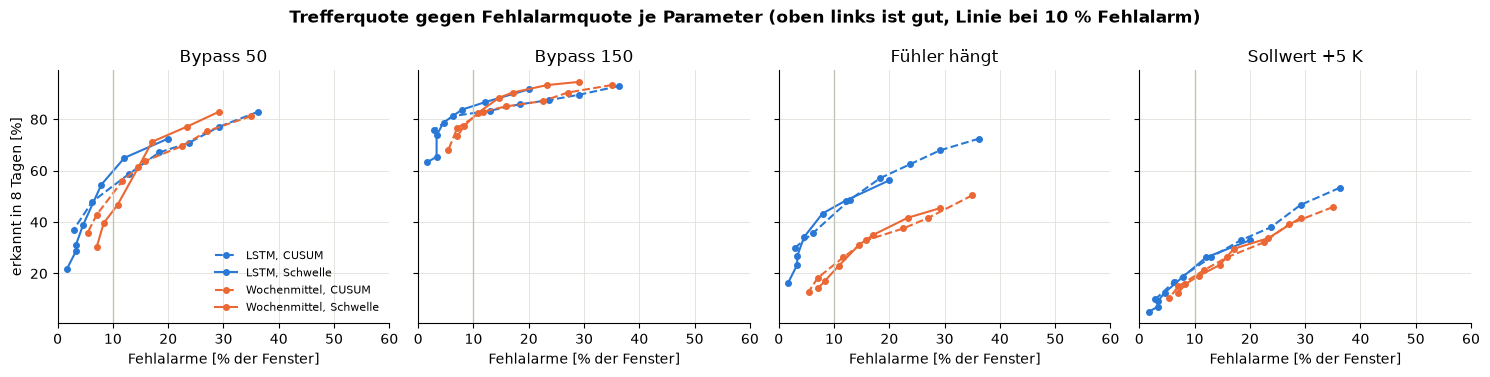

In [11]:
def beste_bei_fehlalarm(tafel, grenze=0.10):
    zeilen = []
    for (erwartung, regel), g in tafel.groupby(level=[0, 1]):
        ok = g[g["ohne"] <= grenze]
        wahl = ok.iloc[0] if len(ok) else g.sort_values("ohne").iloc[0]     # kleinster Parameter mit ≤ 10 %
        zeilen.append({"Erwartung": "Prognose-LSTM" if erwartung == "lstm" else "Wochenmittel", "Regel": regel,
                       "Parameter": wahl.name[2], **wahl.to_dict()})
    return pd.DataFrame(zeilen).rename(columns={"ohne": "Fehlalarm"})

inj_vergleich = beste_bei_fehlalarm(inj)
display(inj_vergleich.round(2))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
stil = {("lstm", "Schwelle"): (FARBE["blau"], "-"), ("lstm", "CUSUM"): (FARBE["blau"], "--"),
        ("wochenmittel", "Schwelle"): (FARBE["orange"], "-"), ("wochenmittel", "CUSUM"): (FARBE["orange"], "--")}
for ax, fehler in zip(axes, FEHLER[1:]):
    for (erwartung, regel), g in inj.groupby(level=[0, 1]):
        farbe, linie = stil[(erwartung, regel)]
        name = ("LSTM" if erwartung == "lstm" else "Wochenmittel") + f", {regel}"
        ax.plot(g["ohne"] * 100, g[fehler] * 100, linie, marker="o", ms=4, lw=1.5, color=farbe, label=name)
    ax.axvline(10, color="#c3c2b7", lw=1)
    ax.set_title(fehler)
    ax.set_xlabel("Fehlalarme [% der Fenster]")
    ax.set_xlim(0, 60)
axes[0].set_ylabel("erkannt in 8 Tagen [%]")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Trefferquote gegen Fehlalarmquote je Parameter (oben links ist gut, Linie bei 10 % Fehlalarm)", fontweight="bold")
fig.tight_layout()
plt.show()

**Was macht diese Zelle?**
- Wählt je Erwartung und Regel den Parameter, der in Fenstern ohne Fehler höchstens 10 % Fehlalarme gibt,
  und zeigt dort die Trefferquoten. Erst damit ist der Vergleich fair.
- Das Bild zeigt die ganze Kurve: Jede Linie ist ein Kandidat, jeder Punkt ein Parameter. Wer bei gleicher
  Fehlalarmquote höher liegt, ist besser.

**Ergebnis**

Die Kontrolle stimmt: Die Schwellenregel des LSTM mit z ≥ 4 ergibt genau die Zahlen aus Notebook 21.
Bei höchstens 10 % Fehlalarmen in 8 Tagen:

| Erwartung | Regel | Fehlalarm | Bypass 50 l/h | Bypass 150 l/h | Fühler hängt | Sollwert +5 K |
|---|---|---|---|---|---|---|
| **Prognose-LSTM** | **Schwelle z ≥ 4** | 8 % | **55 %** | **84 %** | **43 %** | **19 %** |
| Prognose-LSTM | CUSUM h = 20 | 6 % | 48 % | 81 % | 36 % | 17 % |
| Wochenmittel | Schwelle z ≥ 7 | 8 % | 40 % | 78 % | 17 % | 16 % |
| Wochenmittel | CUSUM h = 20 | 7 % | 43 % | 77 % | 18 % | 15 % |

- **Für plötzliche Fehler ist das LSTM der beste Wächter.** Bei gleicher Fehlalarmquote findet es einen
  hängenden Fühler zweieinhalbmal so oft wie das Wochenmittel (43 % gegen 17 %), einen kleinen Bypass
  deutlich öfter (55 % gegen 40 %).
- **Hier ist die Schwellenregel die richtige.** Ein plötzlicher Fehler ist ein großer Sprung, den die Schwelle
  sofort sieht; der CUSUM braucht für dieselbe Fehlalarmquote eine sehr hohe Grenze und ist dann langsamer.
- Ein verstellter Sollwert (+5 K) bleibt für alle schwer (15 bis 19 %): Er verschiebt nur, was das Netz nach
  einigen Tagen als normal übernimmt. Genau dafür ist die Kennlinie mit CUSUM da (Teil A oben).

In [12]:
FALL, DATUM = 68956351, pd.Timestamp("2024-09-09")
ventilfall = []
for name, alarme in kandidaten_a.items():
    tage_bis = ps.erster_alarm_nach(alarme, FALL, DATUM, bis_tage=60)
    ventilfall.append({"Kandidat": name, "erster Alarm nach der Begehung [Tage]": tage_bis if tage_bis is not None else "keiner in 60 Tagen"})

last = []
for name, alarme in kandidaten_a.items():
    eigene = eigene_tage.get(name, lstm_beob)
    eigene = eigene[pd.to_datetime(eigene["datum"]) >= AB]
    a = alarme[pd.to_datetime(alarme["datum"]) >= AB]
    a = ps.auf_tagen(a, eigene)
    last.append({"Kandidat": name, "Alarme je Station und Jahr": ps.alarme_je_jahr(a, eigene)})
pd.DataFrame(ventilfall).merge(pd.DataFrame(last), on="Kandidat").round(1)

,Kandidat,erster Alarm nach der Begehung [Tage],Alarme je Station und Jahr
0,Normalverhaltensmodell (NB 17),2,3.5
1,Tagesmonitor,2,3.7
2,"Prognose-LSTM, Schwelle",7,3.8
3,"Prognose-LSTM, CUSUM",4,4.2
4,"Wochenmittel, Schwelle",1,5.7
5,"Wochenmittel, CUSUM",1,4.9
6,Kennlinienmonitor (NB 14),3,4.8
7,Tagesmonitor ohne Netzereignisse (NB 24),2,3.7
8,"ARIMA-Wächter, Schwelle",27,5.2
9,"ARIMA-Wächter, CUSUM",26,5.2


**Was macht diese Zelle?**
- **Ventilfall 68956351:** Das Ventil stand rund drei Jahre offen und wurde am 09.09.2024 getauscht. Wie
  viele Tage nach dem Tausch meldet jeder Kandidat die Veränderung?
- **Alarmlast:** Alarme je Station und Jahr ab Juni 2024, jeder Kandidat auf seinen **eigenen** Tagen
  (das LSTM auch im Sommer). Das ist die Menge, die im Betrieb auf dem Tisch landen würde.

**Ergebnis**

- **Ventilfall 68956351:** Kennlinie und Tagesmonitor melden den Tausch nach 2 Tagen, das Wochenmittel nach 1,
  der Kennlinienmonitor nach 3, das LSTM mit CUSUM nach 4 und mit Schwelle nach 7 Tagen, die Dynamik aus NB 10 nach 6.
  Der ARIMA-Wächter braucht 26 bis 27 Tage, die übrigen Detektoren aus NB 10 melden ihn in 60 Tagen nicht.
- **Alarmlast:** Kennlinie und LSTM liegen bei 3,5 bis 3,8 Alarmen je Station und Jahr, das LSTM überwacht
  dabei auch den Sommer. Wochenmittel, Kennlinienmonitor und ARIMA alarmieren mit 4,8 bis 5,7 deutlich öfter.

**Fazit Alarm:** Zwei Wächter mit verschiedenen Aufgaben, beide für den Betrieb:
1. **Tagesmonitor** (Kennlinie + CUSUM) für schleichende und bleibende Veränderungen im Heizbetrieb, belegt an
   echten Begehungen. Er ist der Hauptkanal; seine Verschlechterungsalarme bestimmen die Reihenfolge innerhalb
   einer Dringlichkeitsstufe (Abschnitt 4).
2. **Prognose-LSTM** (Schwelle z ≥ 4) für plötzliche große Fehler, auch im Sommer, belegt an eingerechneten
   Fehlern, nicht an echten. Seine Alarme sind ein Hinweis, keine Dringlichkeit, bis es an echten Fällen
   bestätigt ist.

## 3 · Teil B: Fehler erkennen – welche Stationen haben einen Dauerfehler?

Ein Wächter vergleicht jede Station mit sich selbst. Eine Station, die **von Anfang an** schlecht läuft
(z. B. ein Ventil, das seit Jahren offen steht), findet er nie. Dafür braucht es einen Vergleich über
die Stationen: Wer sieht aus wie die Stationen, an denen die Begehung einen Fehler gefunden hat?

**Prüfbasis:** die 53 begangenen Zähler, für die alle Kandidaten einen Wert haben (wie NB 20 und 22),
mit den Befunden aus Kästchen und Freitext (NB 18). Alle Werte stammen aus Daten **vor** der ersten
Begehung. Gelernte Modelle liefern ihren Wert aus der verschachtelten Kreuzvalidierung, haben die
Station also nie gesehen.

| Kandidat | Art | Quelle |
|---|---|---|
| Regelwerk aus dem README (`fault_detection.py`): Sommer-Median Durchfluss, Winter-Rücklauf, Spreizung, Spitzenlast zum Anschluss | Regel | erste Baseline des Projekts, Merkmale aus `features.py` im Jahr vor der Begehung |
| Sommernacht-Regel: Anteil der Sommernächte mit Durchfluss | Regel | NB 18/20 |
| Sommer-Nachtdurchfluss, Rücklauf bei 0 °C, lastgewichteter Rücklauf | Regel | NB 18 |
| K-Means „schlechter“ | ohne Label gelernt | NB 19 |
| Netzvergleich-Score Winter 23/24 | Regel gegen die Flotte | Kennlinien-Strang (`netzvergleich.py`) |
| Abkühlung bei 5 °C im Referenzjahr | Normkennzahl | NB 17 |
| Logistische Regression auf Kennzahlen | gelernt | NB 20/22 |
| LSTM-Embedding allein | gelernt | NB 20 |
| **Logistische Regression auf Kennzahlen + LSTM** | gelernt | NB 22, Paket `fehlerklassen` |

In [13]:
fk_paket = fk.lade()
kz = pd.read_csv(PROCESSED / "modell_kennzahlen.csv", index_col="zaehler")
emb = pd.read_csv(PROCESSED / "lstm_embedding.csv", index_col="zaehler")
lstm_scores = pd.read_csv(PROCESSED / "lstm_scores.csv", index_col="zaehler")
basis = fk.trainingsdaten(kz, emb, labels)
oof = fk_paket["kreuzvalidierung"]
print(f"Prüfbasis: {len(basis)} begangene Zähler; Ventil {int(basis['ventil'].sum())}, Dämmung {int(basis['daemmung'].sum())}, "
      f"überdimensioniert {int(basis['ueberdimensioniert'].sum())} von {basis['ueberdimensioniert'].notna().sum()}")

# Regelwerk aus dem README: Merkmale im Jahr vor der Begehung (spätestens Stichtag)
grenze = fk.grenze_vor_begehung(labels, kz.index)
anschluss = fk.lade_anschlusswerte()
readme = {}
for z in kz.index:
    pfad = PROCESSED / "real_meters" / f"{z}.csv"
    df = pd.read_csv(pfad, parse_dates=["Timestamp"]).rename(columns={
        "Energy (kWh)": "energy", "Volume flow (l/h)": "flow", "Power (kW)": "power", "Temperature difference (°C)": "dt",
        "Flow temperature (°C)": "vl", "Return temperature (°C)": "rt", "Volume (m³)": "volume"}).set_index("Timestamp")
    df = df[(df.index >= grenze[z] - pd.DateOffset(years=1)) & (df.index < grenze[z])].dropna(subset=["flow", "rt"])
    if len(df) < 24 * 60:
        continue
    df["month"], df["hour"] = df.index.month, df.index.hour
    readme[z] = features_for_meter(df, anschluss.get(z))
readme = pd.DataFrame(readme).T
readme_flags = fd.classify_dataframe(readme)
kalibriert, _ = rk.kalibriere(readme)
print(f"README-Merkmale für {len(readme)} Zähler; Regeln treffen mit Vorgabeschwellen:",
      readme_flags["predicted_fault"].value_counts().to_dict())

Prüfbasis: 53 begangene Zähler; Ventil 11, Dämmung 22, überdimensioniert 9 von 35


README-Merkmale für 90 Zähler; Regeln treffen mit Vorgabeschwellen: {'fouled_filter': 38, 'excess_rt': 33, 'control_hysteresis': 15, 'continuous_flow': 4}


**Was macht diese Zelle?**
- Lädt das Paket `fehlerklassen` mit den Werten aus der Kreuzvalidierung und die Prüfbasis von NB 22.
- Rechnet das **erste Regelwerk des Projekts** (README, `src/fault_detection.py`) nach, diesmal nur auf
  dem Jahr vor der ersten Begehung, damit es dieselbe Zeit sieht wie die anderen Kandidaten. Dazu die
  Schwellen von `src/regelkalibrierung.py` (oberste 15 % der echten Verteilung).

In [14]:
# Netzvergleich des Kennlinien-Strangs: gerechnet in Teil A (weitere Wächter)
markiert = netz["markiert"]
w2324 = markiert[markiert["winter"] == "23/24"].set_index("meter")
from src import empfehlung as em
from src import netzvergleich as nv
from src import vergleichsgruppen as vg
seb_stationen = pd.read_csv(PROCESSED / "normalmodell_stationen.csv", index_col="zaehler")

ventil_kandidaten = {
    "README: Sommer-Median Durchfluss": readme["summer_flow_baseline"],
    "README: Winter-Rücklauf": readme["rt_mean_winter"],
    "README: Spreizung unter Last (niedrig)": -readme["dt_mean_loaded"],
    "Sommernacht-Regel (Anteil mit Durchfluss)": kz["sommer_durchlauf_anteil"],
    "Sommer-Nachtdurchfluss": kz["sommer_nachtfluss_lph"],
    "Rücklauf bei 0 °C": kz["winter_ruecklauf_bei_0c"],
    "Rücklauf lastgewichtet": kz["ruecklauf_lastgewichtet"],
    "K-Means „schlechter“": (fk.kmeans_einstufen(fk_paket["kmeans"], kz) == "schlechter").astype(float),
    "Netzvergleich-Score 23/24": w2324["score"],
    "Abkühlung bei 5 °C (niedrig)": -seb_stationen["norm_referenz"],
    "LR Kennzahlen": lstm_scores["ventil | Kennzahlen (alle)"],
    "LSTM-Embedding allein": lstm_scores["ventil | LSTM Winter + Sommer"],
    "LR Kennzahlen + LSTM (Paket)": oof["ventil"],
}
y_ventil = basis["ventil"].astype(int)
ventil_tab = ps.bewerte_scores(y_ventil.loc[basis.index], {k: v.reindex(basis.index) for k, v in ventil_kandidaten.items()},
                               bezug="Sommernacht-Regel (Anteil mit Durchfluss)")
ventil_tab.sort_values("AUC", ascending=False).round(3)

,Kandidat,Stationen,Befunde,AUC,unten,oben,P@10,p (Zufall),Δ zum Bezug,Δ unten,Δ oben,p (Holm),besser als Raten,gegen Bezug
12,LR Kennzahlen + LSTM (Paket),52,11,0.889,0.775,0.977,0.7,0.000,0.040,-0.041,0.145,0.001,True,nicht unterscheidbar
4,Sommer-Nachtdurchfluss,52,11,0.877,0.729,0.993,0.7,0.000,0.028,-0.024,0.087,0.001,True,nicht unterscheidbar
0,README: Sommer-Median Durchfluss,52,11,0.850,0.685,0.982,0.7,0.000,0.001,-0.064,0.063,0.002,True,nicht unterscheidbar
3,Sommernacht-Regel (Anteil mit Durchfluss),52,11,0.849,0.673,0.982,0.7,0.000,NaN,NaN,NaN,0.003,True,Bezug
1,README: Winter-Rücklauf,52,11,0.840,0.679,0.964,0.6,0.000,-0.009,-0.138,0.151,0.001,True,nicht unterscheidbar
11,LSTM-Embedding allein,52,11,0.836,0.705,0.942,0.5,0.000,-0.013,-0.124,0.123,0.003,True,nicht unterscheidbar
10,LR Kennzahlen,52,11,0.792,0.576,0.969,0.6,0.001,-0.058,-0.146,0.015,0.009,True,nicht unterscheidbar
5,Rücklauf bei 0 °C,52,11,0.765,0.590,0.917,0.5,0.004,-0.084,-0.242,0.069,0.027,True,nicht unterscheidbar
6,Rücklauf lastgewichtet,52,11,0.749,0.560,0.919,0.5,0.006,-0.100,-0.288,0.097,0.029,True,nicht unterscheidbar
2,README: Spreizung unter Last (niedrig),52,11,0.738,0.537,0.919,0.6,0.009,-0.111,-0.256,0.008,0.037,True,nicht unterscheidbar


**Was macht diese Zelle?**
- Rechnet den Netzvergleich des Kennlinien-Strangs (`stationsblatt.rechne`) und nimmt seinen Score aus
  dem Winter 23/24, also vor den Begehungen im Herbst 2024.
- Stellt **alle Kandidaten fürs Ventil** zusammen. Jeder liefert einen Wert je Station, größer heißt
  verdächtiger (wo nötig mit Minus umgedreht).
- `ps.bewerte_scores` bewertet alle auf **denselben Stationen**: AUC mit 95-%-Intervall, wie viele der 10
  verdächtigsten wirklich einen Befund hatten (P@10), Zufallstest mit Holm-Korrektur, und die gepaarte
  Differenz zur einfachsten guten Regel (Sommernacht-Regel) als Bezug.
- Stationen ohne Wert bei einem Kandidaten fallen für **alle** heraus (Regel 3). Die Zahl steht in `Stationen`.

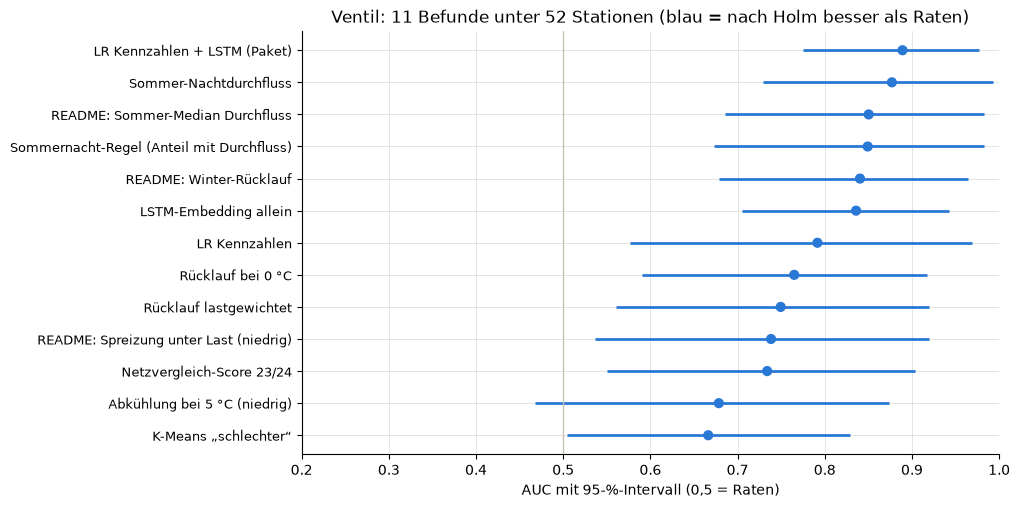

In [15]:
def wald(tab, titel, ax):
    t = tab.sort_values("AUC")
    farben = [FARBE["blau"] if b else FARBE["grau"] for b in t["besser als Raten"]]
    y = np.arange(len(t))
    ax.hlines(y, t["unten"], t["oben"], color=farben, lw=2)
    ax.scatter(t["AUC"], y, color=farben, s=40, zorder=3)
    ax.axvline(0.5, color="#c3c2b7", lw=1)
    ax.set_yticks(y, t["Kandidat"], fontsize=9)
    ax.set_xlim(0.2, 1.0)
    ax.set_xlabel("AUC mit 95-%-Intervall (0,5 = Raten)")
    ax.set_title(titel)

fig, ax = plt.subplots(figsize=(9, 5.5))
wald(ventil_tab, f"Ventil: {int(ventil_tab['Befunde'].iloc[0])} Befunde unter {int(ventil_tab['Stationen'].iloc[0])} Stationen (blau = nach Holm besser als Raten)", ax)
plt.show()

**Was macht diese Zelle?**
- Zeigt jede AUC mit ihrem Intervall. Blau: nach Holm-Korrektur besser als Raten. Überlappen sich zwei
  Intervalle stark, sind die beiden Kandidaten nicht unterscheidbar; das sagt die Spalte „gegen Bezug“
  genauer, weil sie gepaart auf denselben Stationen rechnet.

**Ergebnis**

Ventil, 11 Befunde unter 52 begangenen Zählern (ein Zähler fällt heraus, weil ein Kandidat für ihn keinen Wert hat):

| Kandidat | AUC [95 %] | P@10 | gegen Sommernacht-Regel |
|---|---|---|---|
| LR Kennzahlen + LSTM (Paket) | **0,89** [0,78; 0,98] | 7 | +0,04, nicht unterscheidbar |
| Sommer-Nachtdurchfluss (Regel) | 0,88 [0,73; 0,99] | 7 | +0,03, nicht unterscheidbar |
| README: Sommer-Median Durchfluss (Regel) | 0,85 [0,69; 0,98] | 7 | 0,00 |
| Sommernacht-Regel (Bezug) | 0,85 [0,67; 0,98] | 7 | – |
| README: Winter-Rücklauf (Regel) | 0,84 [0,68; 0,96] | 6 | −0,01 |
| LSTM-Embedding allein | 0,84 [0,71; 0,94] | 5 | −0,01 |
| LR Kennzahlen | 0,79 [0,58; 0,97] | 6 | −0,06 |
| Netzvergleich-Score 23/24 | 0,73 [0,55; 0,90] | 5 | −0,12 |
| Abkühlung bei 5 °C | 0,68 [0,47; 0,87] | 4 | −0,17 |
| K-Means „schlechter“ | 0,67 [0,51; 0,83] | 5 | −0,18, **belegt schlechter** |

- **Alle Kandidaten sind nach Holm-Korrektur besser als Raten.** Ein offenes Ventil ist das deutlichste Fehlerbild im Netz.
- **Kein gelerntes Modell ist belegt besser als die einfachste Regel.** Schon die allererste Regel des Projekts
  (`continuous_flow` aus dem README, Sommer-Median des Durchflusses) erreicht 0,85, wenn man sie nur auf dem Jahr
  vor der Begehung rechnet. Der Vorsprung des Modells (+0,04) liegt innerhalb der Unsicherheit.
- **Wofür das Modell trotzdem gut ist:** Es braucht den Sommer nicht. Ohne Sommerdaten fällt jede Sommerregel aus,
  das Modell urteilt dann aus dem Winter (NB 20: nur Winter LSTM 0,83 gegen Kennzahlen 0,68, knapp belegt). Für
  Folie 5 bleibt es deshalb das Ventil-Modell; die Sommerregel steht als Gegenprobe daneben.
- Clustering (K-Means) und Flottenvergleiche (Netzvergleich, Normkennzahl) erkennen das Ventil schwächer: Sie
  messen „schlechter als andere“, und das ist nur zur Hälfte ein Ventil.

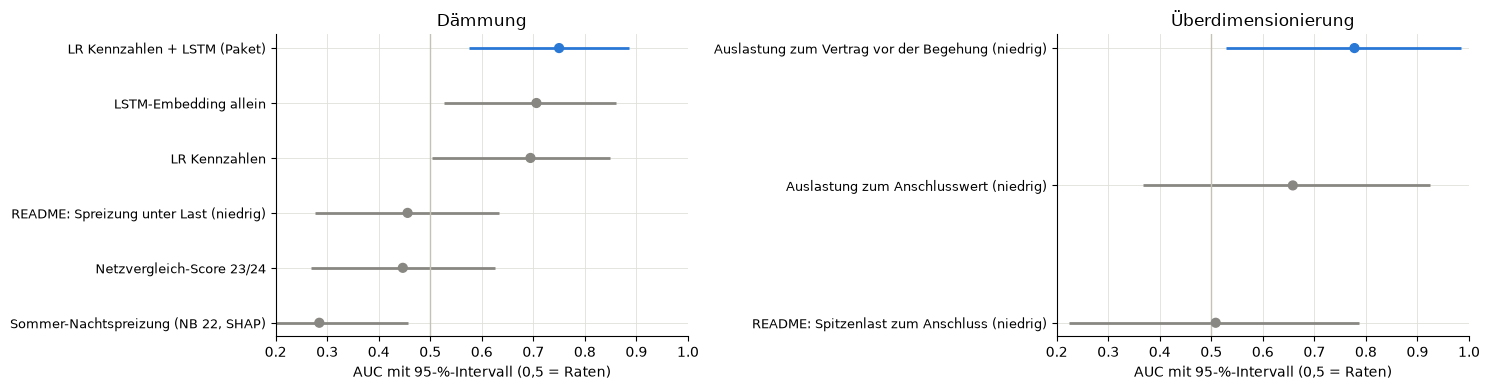

Stationen  Befunde    AUC  unten   oben  P@10  p (Zufall)  Δ zum Bezug  Δ unten  Δ oben  p (Holm)  besser als Raten  \
Ziel                Kandidat                                                                                                                                                                 
Dämmung             Sommer-Nachtspreizung (NB 22, SHAP)                       42       18  0.285  0.139  0.456   0.3       0.992       -0.410   -0.646  -0.138     1.000             False   
                    README: Spreizung unter Last (niedrig)                    42       18  0.456  0.276  0.634   0.5       0.690       -0.238   -0.513   0.065     1.000             False   
                    Netzvergleich-Score 23/24                                 42       18  0.447  0.269  0.625   0.4       0.721       -0.248   -0.515   0.055     1.000             False   
                    LR Kennzahlen                                             42       18  0.694  0.504  0.849   0.8       0.016          NaN      NaN     NaN     0.065             False   
                    LSTM-Embedding allein                                     42       18  0.706  0.527  0.861   0.7       0.011        0.012   -0.172   0.188     0.056             False   
                    LR Kennzahlen + LSTM (Paket)                              42       18  0.750  0.575  0.886   0.8       0.003        0.056   -0.081   0.202     0.019              True   
Überdimensionierung Auslastung zum Vertrag vor der Begehung (niedrig)         35        9  0.778  0.528  0.984   0.6       0.006        0.120    0.023   0.242     0.018              True   
                    Auslastung zum Anschlusswert (niedrig)                    35        9  0.658  0.367  0.924   0.5       0.084          NaN      NaN     NaN     0.168             False   
                    README: Spitzenlast zum Anschluss (niedrig)               35        9  0.509  0.224  0.787   0.4       0.471       -0.150   -0.306  -0.015     0.471             False   

                                                                                gegen Bezug  
Ziel                Kandidat                                                                 
Dämmung             Sommer-Nachtspreizung (NB 22, SHAP)                   belegt schlechter  
                    README: Spreizung unter Last (niedrig)             nicht unterscheidbar  
                    Netzvergleich-Score 23/24                          nicht unterscheidbar  
                    LR Kennzahlen                                                     Bezug  
                    LSTM-Embedding allein                              nicht unterscheidbar  
                    LR Kennzahlen + LSTM (Paket)                       nicht unterscheidbar  
Überdimensionierung Auslastung zum Vertrag vor der Begehung (niedrig)         belegt besser  
                    Auslastung zum Anschlusswert (niedrig)                            Bezug  
                    README: Spitzenlast zum Anschluss (niedrig)           belegt schlechter

In [16]:
daemmung_kandidaten = {
    "Sommer-Nachtspreizung (NB 22, SHAP)": kz["sommer_nacht_spreizung_k"],
    "README: Spreizung unter Last (niedrig)": -readme["dt_mean_loaded"],
    "Netzvergleich-Score 23/24": w2324["score"],
    "LR Kennzahlen": lstm_scores["daemmung | Kennzahlen (alle)"],
    "LSTM-Embedding allein": lstm_scores["daemmung | LSTM Winter + Sommer"],
    "LR Kennzahlen + LSTM (Paket)": oof["daemmung"],
}
daemmung_tab = ps.bewerte_scores(basis["daemmung"].astype(int), {k: v.reindex(basis.index) for k, v in daemmung_kandidaten.items()},
                                 bezug="LR Kennzahlen")

vertrag_basis = basis.dropna(subset=["ueberdimensioniert"])
vertrag_kandidaten = {
    "Auslastung zum Vertrag vor der Begehung (niedrig)": -kz["auslastung_vertrag"],
    "Auslastung zum Anschlusswert (niedrig)": -kz["auslastung"],
    "README: Spitzenlast zum Anschluss (niedrig)": -readme["peak_load_share"],
}
vertrag_tab = ps.bewerte_scores(vertrag_basis["ueberdimensioniert"].astype(int),
                                {k: v.reindex(vertrag_basis.index) for k, v in vertrag_kandidaten.items()},
                                bezug="Auslastung zum Anschlusswert (niedrig)")
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
wald(daemmung_tab, "Dämmung", axes[0])
wald(vertrag_tab, "Überdimensionierung", axes[1])
fig.tight_layout()
plt.show()
pd.concat([daemmung_tab.assign(Ziel="Dämmung"), vertrag_tab.assign(Ziel="Überdimensionierung")]).set_index(["Ziel", "Kandidat"]).round(3)

**Was macht diese Zelle?**
- Dieselbe Prüfung für **Dämmung** (Bezug: logistische Regression auf Kennzahlen) und für die
  **Überdimensionierung** (nur 35 begangene Zähler mit eingetragenem Vertrag). Bei der Überdimensionierung
  ist der Bezug die Auslastung zum Anschlusswert aus `Nodes_Edges.ods`. Notebook 18 hat gezeigt, dass dieser
  Wert bei 7 von 9 verkleinerten Verträgen schon der **neue** ist.

**Ergebnis**

- **Dämmung** (18 Befunde unter 42 Zählern, die alle Kandidaten haben): Nur das Paket-Modell (LR Kennzahlen +
  LSTM, 0,75 [0,58; 0,89]) ist nach Holm besser als Raten. Es ist aber nicht belegt besser als die LR auf den
  Kennzahlen allein (+0,06).
- **Eine Deutung aus Notebook 22 hält nicht:** Dort lag die Spreizung in Sommernächten bei XGBoost vorne, mit der
  Erklärung, ungedämmte Leitungen ließen das Wasser nachts abkühlen und die Spreizung **steige**. Als Regel in
  dieser Richtung, vorab festgelegt, kommt sie auf 0,29: Stationen mit Dämmungsbefund haben im Sommer eine
  **kleinere** Nachtspreizung. SHAP sagt, *dass* ein Merkmal zählt, nicht in welche Richtung. Die Deutung in NB 22
  sollte angepasst werden.
- **Überdimensionierung** (9 von 35): Die Auslastung zum **Vertrag vor der Begehung** ist belegt besser als zum
  Anschlusswert (+0,12 [0,02; 0,24]). Die README-Regel `oversized_contract` (Spitzenlast zum Anschluss) liegt bei
  Raten (0,51) und belegt darunter, weil sie den Anschlusswert nimmt, der oft schon der neue Vertrag ist.

### Weitere Erkenner aus dem Projekt

Jedes übrige Notebook, das je Station eine Zahl liefert, die „verdächtiger“ heißen kann, kommt hier dazu. Alle Werte
stammen wie oben aus der Zeit **vor** der ersten Begehung (Winter 23/24 bzw. das Jahr davor).

| Kandidat | Notebook | Wert je Station |
|---|---|---|
| Kennliniensteigung (niedrig), Residuenstreuung, Anteil Rücklauf über 50 °C | 13 (Stationsbilder), über den Netzvergleich im Winter 23/24 | festsitzender Durchfluss, unruhige Kennlinie, Dauerlinie |
| Durchflussanteil der Modulation (niedrig) | 12 (Ternär), `fallsammlung` | spreizungsgeregelt statt durchflussgeregelt |
| Kurzschluss-Zeitanteil | 04, 09, 10 | Anteil der Stunden im Stundencluster mit hohem Durchfluss und kleiner Spreizung |
| Persistenzanteil Netzresiduum, stationseigenes Residuum, Isolation Forest | 10 | Anteil persistent auffälliger Tage |
| Schweregrad-Punkte | 11 | Abweichung, Persistenz, Mehrdurchfluss |
| Anteil schlechtester Tagestyp | 06 | Tage im Cluster mit dem wärmsten Rücklauf seiner Temperaturgruppe |
| Potenzial-Score | 27 | Abstand zum besten Viertel |
| Vergleichsgruppen-Score | `23_nachbarn` | Netzvergleich gegen die 15 Stationen mit ähnlicher Wärmemenge |
| Random Forest, XGBoost auf allen Merkmalen | 22 | verschachtelt kreuzvalidiert wie dort |

Damit keine Station herausfällt, nur weil ein einzelner Kandidat sie nicht kennt, wird hier **paarweise** geprüft:
jeder Kandidat auf den Stationen, auf denen er und der Bezug einen Wert haben. Verglichen wird über die gepaarte
Differenz zum Bezug.

In [17]:
grenze_tag = labels["erste_begehung"].clip(upper=fk.STICHTAG).reindex(sorted(set(panel["meter"]))).fillna(fk.STICHTAG)


def jahr_davor(tab, spalte_meter="meter", spalte_datum="datum"):
    g = tab[spalte_meter].map(grenze_tag)
    d = pd.to_datetime(tab[spalte_datum])
    return tab[(d < g) & (d >= g - pd.Timedelta(days=365))]


# Notebook 10 und 11: Persistenzanteile, Kurzschluss-Zeitanteil, Schweregrad
p_def = panel.copy()
for spalte in (f"score_{an.D_RESID_NETZ}", f"score_{an.D_RESID_STATION}", f"score_{an.D_IFOREST}"):
    p_def, _ = an.persistente_tage(p_def, spalte)
vor = jahr_davor(p_def)
vor.attrs["kurzschlusscluster"] = KURZ
kenn11 = em.kennzahlen(vor, ANTEIL)
grad11 = em.schweregrad(kenn11, em.effizienz(vor, kenn11)).set_index("meter")

# Notebook 06: Anteil der Tage im Tagestyp mit dem wärmsten Rücklauf seiner Temperaturgruppe
hast_tage = pd.read_csv(PROCESSED / "hast_tage.csv", parse_dates=["datum"])
nutz = hast_tage[hast_tage["nutzbar"] & hast_tage["cluster"].notna()]
schlechtest = nutz.groupby(["gruppe", "cluster"])["ruecklauf_c"].median().groupby(level=0).idxmax().tolist()
nutz = nutz.assign(schlechtest=[(g, c) in schlechtest for g, c in zip(nutz["gruppe"], nutz["cluster"])])
typ06 = jahr_davor(nutz, "zaehler", "datum").groupby("zaehler")["schlechtest"].mean()

# Notebook 27 und 23_nachbarn: Potenzial und Vergleichsgruppen im Winter 23/24
pot27 = netz["potenzial"]
pot27 = pot27[pot27["winter"] == "23/24"].set_index("meter")["potenzial_score"]
gruppe = vg.gruppenbezug(netz["tabelle"], vg.winterenergie(netz["punkte"]))
gruppe = nv.markiere(gruppe, netz["kennzahlen"])
vg2324 = gruppe[gruppe["winter"] == "23/24"].set_index("meter")["score"]

weitere_ventil = {
    "NB 13: Kennliniensteigung (niedrig)": -w2324["steigung"],
    "NB 13: Residuenstreuung der Kennlinie": w2324["residuum_sd"],
    "NB 13: Anteil Rücklauf über 50 °C": w2324["rl_ueber_50_anteil"],
    "NB 12/fallsammlung: Durchflussanteil der Modulation (niedrig)": -kz["anteil_volumenstrom"],
    "NB 09/10: Kurzschluss-Zeitanteil": vor.groupby("meter")[ANTEIL].mean(),
    "NB 10: Persistenz Netzresiduum": vor.groupby("meter")[f"persistent_score_{an.D_RESID_NETZ}"].mean(),
    "NB 10: Persistenz stationseigenes Residuum": vor.groupby("meter")[f"persistent_score_{an.D_RESID_STATION}"].mean(),
    "NB 10: Persistenz Isolation Forest": vor.groupby("meter")[f"persistent_score_{an.D_IFOREST}"].mean(),
    "NB 11: Schweregrad-Punkte": grad11["punkte"],
    "NB 06: Anteil schlechtester Tagestyp": typ06,
    "NB 27: Potenzial-Score 23/24": pot27,
    "23_nachbarn: Vergleichsgruppen-Score 23/24": vg2324,
}
print({k: int(v.reindex(basis.index).notna().sum()) for k, v in weitere_ventil.items()})

{'NB 13: Kennliniensteigung (niedrig)': 53, 'NB 13: Residuenstreuung der Kennlinie': 53, 'NB 13: Anteil Rücklauf über 50 °C': 53, 'NB 12/fallsammlung: Durchflussanteil der Modulation (niedrig)': 53, 'NB 09/10: Kurzschluss-Zeitanteil': 53, 'NB 10: Persistenz Netzresiduum': 53, 'NB 10: Persistenz stationseigenes Residuum': 53, 'NB 10: Persistenz Isolation Forest': 53, 'NB 11: Schweregrad-Punkte': 53, 'NB 06: Anteil schlechtester Tagestyp': 53, 'NB 27: Potenzial-Score 23/24': 53, '23_nachbarn: Vergleichsgruppen-Score 23/24': 53}


**Was macht diese Zelle?**
- Schneidet das Tagespanel aus Notebook 10 auf das **Jahr vor der ersten Begehung** (spätestens Stichtag) und rechnet
  daraus die Persistenzanteile, den Kurzschluss-Zeitanteil und die Schweregrad-Punkte von Notebook 11 mit dessen
  Funktionen.
- Notebook 06: Der schlechteste Tagestyp ist je Temperaturgruppe der Cluster mit dem wärmsten Rücklauf; gezählt wird
  der Anteil der Tage einer Station darin.
- Notebook 27 und `23_nachbarn`: Potenzial-Score und Vergleichsgruppen-Score im Winter 23/24 aus dem Kennlinien-Strang.
- Die letzte Zeile zeigt, für wie viele der 53 begangenen Prüfzähler jeder Kandidat einen Wert hat.

In [18]:
# Notebook 22: Random Forest und XGBoost auf allen Merkmalen, verschachtelt kreuzvalidiert wie dort
import xgboost
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, LeaveOneOut, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

prog = pd.read_csv(PROCESSED / "prognose_tage.csv", parse_dates=["tag"])
vorher_prog = prog[prog["abschnitt"].isin(["Validierung", "Test (Sommer 2024)"])].copy()
vorher_prog["auffaellig"] = (vorher_prog["z_rl"].abs() >= 3) | (vorher_prog["z_fluss"].abs() >= 3)
waechter_merkmale = vorher_prog.groupby("zaehler").agg(waechter_res_rl=("res_rl", "mean"),
                                                        waechter_res_fluss_nacht=("res_fluss_nacht", "mean"),
                                                        waechter_anteil_auffaellig=("auffaellig", "mean"))
alle_merkmale = fk.MERKMALE + list(waechter_merkmale.columns)
X_alle = basis.join(waechter_merkmale)[alle_merkmale]


class XGBAusgeglichen(XGBClassifier):
    def fit(self, X, y, **kwargs):
        self.set_params(scale_pos_weight=(len(y) - np.sum(y)) / max(np.sum(y), 1))
        return super().fit(X, y, **kwargs)


BAUM = {
    "NB 22: Random Forest (alle Merkmale)": (
        make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(
            n_estimators=300, class_weight="balanced_subsample", random_state=0, n_jobs=1)),
        {"randomforestclassifier__max_depth": [2, 4, None], "randomforestclassifier__min_samples_leaf": [2, 5]}),
    "NB 22: XGBoost Tiefe 2–3 (alle Merkmale)": (
        XGBAusgeglichen(subsample=0.8, colsample_bytree=0.8, min_child_weight=2, n_jobs=1, random_state=0, verbosity=0),
        {"max_depth": [2, 3], "learning_rate": [0.05, 0.15], "n_estimators": [100, 300]}),
}
baum_scores = {"ventil": {}, "daemmung": {}}
for ziel in baum_scores:
    d = basis.dropna(subset=[ziel])
    y = d[ziel].astype(int).to_numpy()
    for name, (schaetzer, raster) in BAUM.items():
        suche = GridSearchCV(schaetzer, raster, cv=StratifiedKFold(4, shuffle=True, random_state=0), scoring="roc_auc")
        p = cross_val_predict(suche, X_alle.loc[d.index], y, cv=LeaveOneOut(), method="predict_proba", n_jobs=-1)[:, 1]
        baum_scores[ziel][name] = pd.Series(p, index=d.index)
print("Baum-Modelle gerechnet:", {z: list(s) for z, s in baum_scores.items()})

Baum-Modelle gerechnet: {'ventil': ['NB 22: Random Forest (alle Merkmale)', 'NB 22: XGBoost Tiefe 2–3 (alle Merkmale)'], 'daemmung': ['NB 22: Random Forest (alle Merkmale)', 'NB 22: XGBoost Tiefe 2–3 (alle Merkmale)']}


**Was macht diese Zelle?**
- Baut die Merkmale von Notebook 22 nach: 13 Kennzahlen, 16 Embedding-Zahlen und 3 Zusammenfassungen des Wächters
  (nur Tage vor der Begehung, die das LSTM nicht gelernt hat).
- Rechnet Random Forest und XGBoost (Tiefe 2–3, mit Wechselwirkungen) mit denselben Rastern und derselben
  verschachtelten Kreuzvalidierung wie Notebook 22. Jede Station bekommt einen Wert aus einem Modell, das sie nie
  gesehen hat.

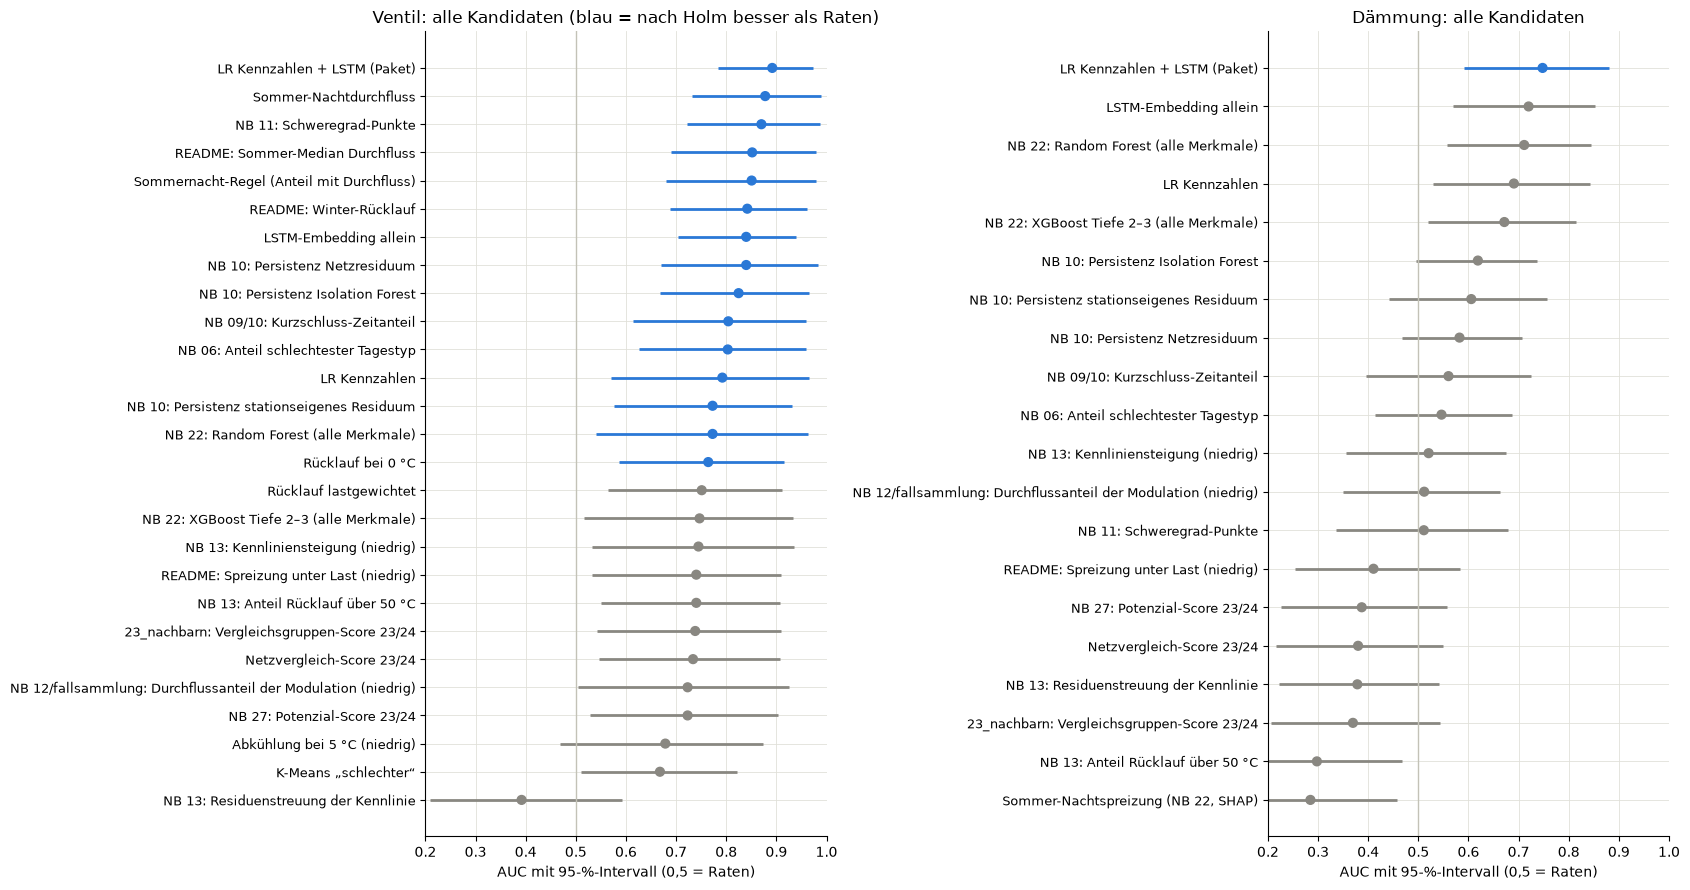

,Kandidat,Stationen,Befunde,AUC,unten,oben,P@10,Δ zum Bezug,Δ unten,Δ oben,p (Holm),besser als Raten,gegen Bezug
12,LR Kennzahlen + LSTM (Paket),53,11,0.892,0.783,0.972,0.7,0.041,-0.039,0.149,0.003,True,nicht unterscheidbar
4,Sommer-Nachtdurchfluss,53,11,0.878,0.733,0.989,0.7,0.027,-0.025,0.085,0.003,True,nicht unterscheidbar
21,NB 11: Schweregrad-Punkte,53,11,0.870,0.722,0.987,0.7,0.019,-0.099,0.134,0.003,True,nicht unterscheidbar
0,README: Sommer-Median Durchfluss,53,11,0.852,0.689,0.980,0.7,0.001,-0.066,0.065,0.003,True,nicht unterscheidbar
3,Sommernacht-Regel (Anteil mit Durchfluss),53,11,0.851,0.679,0.980,0.7,NaN,NaN,NaN,0.006,True,Bezug
1,README: Winter-Rücklauf,53,11,0.842,0.688,0.961,0.6,-0.009,-0.141,0.143,0.003,True,nicht unterscheidbar
18,NB 10: Persistenz Netzresiduum,53,11,0.840,0.670,0.983,0.7,-0.011,-0.141,0.081,0.003,True,nicht unterscheidbar
11,LSTM-Embedding allein,53,11,0.840,0.703,0.940,0.5,-0.011,-0.121,0.130,0.004,True,nicht unterscheidbar
20,NB 10: Persistenz Isolation Forest,53,11,0.825,0.668,0.965,0.7,-0.026,-0.142,0.074,0.003,True,nicht unterscheidbar
17,NB 09/10: Kurzschluss-Zeitanteil,53,11,0.804,0.615,0.960,0.7,-0.047,-0.183,0.067,0.019,True,nicht unterscheidbar


,Kandidat,Stationen,Befunde,AUC,unten,oben,P@10,Δ zum Bezug,Δ unten,Δ oben,p (Holm),besser als Raten,gegen Bezug
5,LR Kennzahlen + LSTM (Paket),53,22,0.748,0.591,0.879,0.9,0.057,-0.070,0.210,0.026,True,nicht unterscheidbar
4,LSTM-Embedding allein,53,22,0.720,0.568,0.853,0.7,0.029,-0.138,0.194,0.074,False,nicht unterscheidbar
18,NB 22: Random Forest (alle Merkmale),53,22,0.711,0.558,0.844,0.7,0.021,-0.127,0.176,0.101,False,nicht unterscheidbar
3,LR Kennzahlen,53,22,0.691,0.529,0.842,0.9,NaN,NaN,NaN,0.167,False,Bezug
19,NB 22: XGBoost Tiefe 2–3 (alle Merkmale),53,22,0.672,0.519,0.814,0.6,-0.019,-0.171,0.137,0.298,False,nicht unterscheidbar
13,NB 10: Persistenz Isolation Forest,53,22,0.619,0.495,0.736,0.7,-0.072,-0.258,0.138,0.403,False,nicht unterscheidbar
12,NB 10: Persistenz stationseigenes Residuum,53,22,0.606,0.442,0.756,0.7,-0.085,-0.326,0.164,1.000,False,nicht unterscheidbar
11,NB 10: Persistenz Netzresiduum,53,22,0.582,0.467,0.706,0.6,-0.109,-0.315,0.119,1.000,False,nicht unterscheidbar
10,NB 09/10: Kurzschluss-Zeitanteil,53,22,0.560,0.395,0.724,0.5,-0.130,-0.372,0.124,1.000,False,nicht unterscheidbar
15,NB 06: Anteil schlechtester Tagestyp,53,22,0.546,0.414,0.686,0.5,-0.144,-0.368,0.103,1.000,False,nicht unterscheidbar


In [19]:
alle_ventil = {**ventil_kandidaten, **weitere_ventil, **baum_scores["ventil"]}
ventil_alle = ps.bewerte_scores(y_ventil.loc[basis.index], {k: v.reindex(basis.index) for k, v in alle_ventil.items()},
                                bezug="Sommernacht-Regel (Anteil mit Durchfluss)", paarweise=True)
alle_daemmung = {**daemmung_kandidaten, **{k: v for k, v in weitere_ventil.items()}, **baum_scores["daemmung"]}
daemmung_alle = ps.bewerte_scores(basis["daemmung"].astype(int), {k: v.reindex(basis.index) for k, v in alle_daemmung.items()},
                                  bezug="LR Kennzahlen", paarweise=True)
fig, axes = plt.subplots(1, 2, figsize=(17, 9))
wald(ventil_alle, "Ventil: alle Kandidaten (blau = nach Holm besser als Raten)", axes[0])
wald(daemmung_alle, "Dämmung: alle Kandidaten", axes[1])
fig.tight_layout()
plt.show()
spalten = ["Kandidat", "Stationen", "Befunde", "AUC", "unten", "oben", "P@10", "Δ zum Bezug", "Δ unten", "Δ oben",
           "p (Holm)", "besser als Raten", "gegen Bezug"]
display(ventil_alle.sort_values("AUC", ascending=False)[spalten].round(3))
daemmung_alle.sort_values("AUC", ascending=False)[spalten].round(3)

**Was macht diese Zelle?**
- Bewertet **alle** Kandidaten fürs Ventil (Bezug Sommernacht-Regel) und für die Dämmung (Bezug LR auf Kennzahlen),
  paarweise mit dem Bezug. Die Holm-Korrektur läuft jetzt über alle Kandidaten einer Fehlerart, ist also strenger
  als oben.
- Für die Dämmung laufen auch die Ventil-Kandidaten mit; die Richtung ist dabei dieselbe wie fürs Ventil und vorab
  festgelegt (größer = verdächtiger), nicht nachträglich umgedreht.

**Ergebnis**

**Ventil**, 27 Kandidaten auf den 53 begangenen Zählern, jeder gepaart mit der Sommernacht-Regel; Holm über alle 27:

| Kandidat | Notebook | AUC [95 %] | gegen Sommernacht-Regel | besser als Raten (Holm) |
|---|---|---|---|---|
| LR Kennzahlen + LSTM (Paket) | 20, 22 | **0,89** [0,78; 0,97] | +0,04, nicht unterscheidbar | ja |
| Sommer-Nachtdurchfluss | 18 | 0,88 [0,73; 0,99] | +0,03 | ja |
| **Schweregrad-Punkte** | 11 | 0,87 [0,72; 0,99] | +0,02 | ja |
| README: Sommer-Median Durchfluss | `fault_detection` | 0,85 [0,69; 0,98] | 0,00 | ja |
| Sommernacht-Regel (Bezug) | 18 | 0,85 [0,68; 0,98] | – | ja |
| README: Winter-Rücklauf | `fault_detection` | 0,84 | −0,01 | ja |
| Persistenz Netzresiduum | 10 | 0,84 | −0,01 | ja |
| LSTM-Embedding allein | 20 | 0,84 | −0,01 | ja |
| Persistenz Isolation Forest | 10 | 0,83 | −0,03 | ja |
| Kurzschluss-Zeitanteil | 09, 10 | 0,80 | −0,05 | ja |
| Anteil schlechtester Tagestyp | 06 | 0,80 | −0,05 | ja |
| LR Kennzahlen | 20, 22 | 0,79 | −0,06 | ja |
| Persistenz stationseigenes Residuum | 10 | 0,77 | −0,08 | ja |
| Random Forest, alle Merkmale | 22 | 0,77 | −0,08 | ja |
| Rücklauf bei 0 °C | 18 | 0,76 | −0,09 | ja |
| XGBoost Tiefe 2–3, alle Merkmale | 22 | 0,75 | −0,10, **belegt schlechter** | nein |
| Kennliniensteigung, RL über 50 °C | 13 | 0,74 bis 0,75 | −0,11 | nein |
| Vergleichsgruppen-, Netzvergleich-, Potenzial-Score | `23_nachbarn`, `netzvergleich`, 27 | 0,72 bis 0,74 | −0,11 bis −0,13 | nein |
| Durchflussanteil der Modulation | 12, `fallsammlung` | 0,72 | −0,13 | nein |
| Abkühlung bei 5 °C | 17 | 0,68 | −0,17 | nein |
| K-Means „schlechter“ | 19 | 0,67 | −0,18, **belegt schlechter** | nein |
| Residuenstreuung der Kennlinie | 13 | 0,39 | −0,46, **belegt schlechter** (umgekehrt) | nein |

- **An der Spitze ändert sich nichts.** Das Paket-Modell bleibt vorn, und kein Kandidat ist belegt besser als die
  Sommernacht-Regel. Fast gleichauf liegen Kandidaten, die mit dem Ventil nichts zu tun haben sollten: die
  Schweregrad-Punkte aus Notebook 11 (0,87) und die Persistenz des Netzresiduums (0,84). Sie messen „Rücklauf
  dauerhaft zu warm“, und das ist bei einem offenen Ventil der Fall.
- **Bäume bringen auch mit allen Merkmalen nichts** (Random Forest 0,77, XGBoost 0,75 und belegt schlechter als die
  Regel). Das bestätigt Notebook 22.
- **Flottenvergleiche erkennen das Ventil schwächer** (Netzvergleich, Vergleichsgruppen, Potenzial, K-Means 0,67 bis
  0,74), weil „schlechter als andere“ nur zur Hälfte ein Ventil ist. Eine **unruhige** Kennlinie (Residuenstreuung)
  spricht sogar **gegen** ein Ventil: Ein offenes Ventil läuft gleichmäßig durch.

**Dämmung** (22 von 53):
- **Nur das Paket-Modell ist nach Holm besser als Raten** (0,75 [0,59; 0,88]).
- Alle Flotten- und Rücklaufmaße zeigen die **umgekehrte** Richtung, belegt schlechter als der Bezug: Netzvergleich
  0,38, Vergleichsgruppen 0,37, Potenzial 0,39, Anteil RL über 50 °C 0,30, Nachtspreizung im Sommer 0,29. Ein
  Dämmungsbefund kommt also eher bei Stationen vor, die im Netzvergleich **gut** aussehen.
- Das passt nicht zur Vorstellung, schlechte Dämmung zeige sich am Zähler. Eher wurde gedämmt, wo Monteure ohnehin
  Zeit hatten, oder die Freitext-Kodierung „Dämmung“ meint Arbeiten, die nichts mit dem Messbild zu tun haben (NB 31,
  offene Punkte). Für den Bericht heißt das: Der Hinweis „Dämmung prüfen“ ist statistisch erkennbar, aber
  physikalisch nicht erklärt.

In [20]:
regel_ja_nein = {
    "README continuous_flow (Vorgabe 25 l/h)": (readme_flags["predicted_fault"].eq("continuous_flow")
                                                | readme_flags["reasons"].str.contains("summer median flow")),
    "README excess_rt (Vorgabe 48 °C)": readme_flags["reasons"].str.contains("winter return temperature|return > 50", regex=True),
    "README, kalibriert: Sommer-Median > Q85": readme["summer_flow_baseline"] > kalibriert.get("summer_flow_baseline", np.inf),
    "Sommernacht-Regel ≥ 0,5": kz["sommer_durchlauf_anteil"] >= 0.5,
    "K-Means „schlechter“": fk.kmeans_einstufen(fk_paket["kmeans"], kz) == "schlechter",
    "Netzvergleich auffällig 23/24": w2324["auffaellig"].astype(bool),
    "Klasse „Regelventil tauschen“ (Paket, p ≥ 0,5)": oof["ventil"] >= fk_paket["parameter"]["ventil_grenze"],
}
ja_nein = pd.DataFrame({name: ps.vierfelder(v.reindex(basis.index), basis["ventil"]) for name, v in regel_ja_nein.items()}).T
ja_nein.round(2)

,Stationen,richtig ja,falsch ja,übersehen,richtig nein,Precision,Trefferquote,Basisrate
README continuous_flow (Vorgabe 25 l/h),53.0,8.0,7.0,3.0,35.0,0.53,0.73,0.21
README excess_rt (Vorgabe 48 °C),53.0,10.0,22.0,1.0,20.0,0.31,0.91,0.21
"README, kalibriert: Sommer-Median > Q85",53.0,5.0,2.0,6.0,40.0,0.71,0.45,0.21
"Sommernacht-Regel ≥ 0,5",53.0,9.0,5.0,2.0,37.0,0.64,0.82,0.21
K-Means „schlechter“,53.0,5.0,5.0,6.0,37.0,0.50,0.45,0.21
Netzvergleich auffällig 23/24,53.0,4.0,0.0,7.0,42.0,1.00,0.36,0.21
"Klasse „Regelventil tauschen“ (Paket, p ≥ 0,5)",53.0,8.0,4.0,3.0,38.0,0.67,0.73,0.21


**Was macht diese Zelle?**
- Für die Praxis zählt nicht nur die Reihenfolge (AUC), sondern die **Entscheidung**: Wen schickt man
  hin? Hier jede Regel bzw. Klasse als Ja/Nein gegen den Ventilbefund, auf denselben Stationen.
- **Precision:** Anteil echter Ventilbefunde unter den Stationen mit Ja. **Trefferquote:** Anteil der
  Ventilbefunde, die gefunden werden. Die **Basisrate** ist, was Raten erreichen würde.

**Ergebnis**

Ventil als Ja/Nein, 53 begangene Zähler, Basisrate 21 %:

| Entscheidung | Ja | davon richtig | Precision | Trefferquote |
|---|---|---|---|---|
| Netzvergleich auffällig 23/24 | 4 | 4 | **100 %** | 36 % |
| README kalibriert (oberste 15 %) | 7 | 5 | 71 % | 45 % |
| **Klasse „Regelventil tauschen“** | 12 | 8 | 67 % | **73 %** |
| Sommernacht-Regel ≥ 0,5 | 14 | 9 | 64 % | 82 % |
| README `continuous_flow` (25 l/h) | 15 | 8 | 53 % | 73 % |
| K-Means „schlechter“ | 10 | 5 | 50 % | 45 % |
| README `excess_rt` (48 °C) | 32 | 10 | 31 % | 91 % |

- Die Klasse nach Folie 5 und die Sommernacht-Regel liegen gleichauf: etwa zwei von drei Einsätzen treffen ein
  Ventil, drei von vier Ventilen werden gefunden.
- Der **Netzvergleich** ist das genaueste Signal (4 von 4), findet aber nur ein Drittel. Wo er und die Klasse
  übereinstimmen, ist der Verdacht am sichersten. Das nutzt die Dringlichkeit in Abschnitt 4.
- Die README-Regeln mit den alten Schwellen schlagen zu oft an (`excess_rt` bei 32 von 53). Mit kalibrierten
  Schwellen werden sie brauchbar, bleiben aber hinter der Klasse.

### Gegenprobe nach der Begehung: sinkt der Ventilverdacht, wenn das Ventil getauscht wurde?

Alle Prüfungen oben nutzen Daten **vor** der Begehung. Eine Prüfung mit **neuen Daten** liefert der Winter
danach: Das Paket wird unverändert auf Winter 24/25 und Sommer 2025 angewendet (`fk.saison_bewerten`).
Wo das Ventil getauscht wurde, sollte der Verdacht sinken; bei nie begangenen Stationen mit Verdacht
sollte er bleiben, denn dort hat niemand etwas verändert.

In [21]:
vorher = fk.bewerten(fk_paket, kz, emb, oof=oof)
nachher = fk.saison_bewerten(fk_paket, stunden, ("2024-10-01", "2025-04-01"), ("2025-06-01", "2025-09-01"))
vergleich = vorher[["p_ventil", "klasse"]].join(nachher[["p_ventil", "klasse"]], rsuffix="_2425", how="inner").join(labels[["ventil", "erste_begehung"]])
vergleich["Gruppe"] = np.select(
    [vergleich["ventil"] == True, vergleich["ventil"] == False, vergleich["ventil"].isna()],
    ["begangen, Ventilbefund", "begangen, anderer Befund", "nie begangen"], "")
vergleich["vorher Verdacht"] = vergleich["p_ventil"] >= 0.5
vergleich["Δ p_ventil"] = vergleich["p_ventil_2425"] - vergleich["p_ventil"]
from scipy import stats
zeilen = []
for (gruppe, verdacht), g in vergleich.dropna(subset=["p_ventil_2425"]).groupby(["Gruppe", "vorher Verdacht"]):
    p = stats.wilcoxon(g["Δ p_ventil"]).pvalue if len(g) >= 6 else np.nan
    zeilen.append({"Gruppe": gruppe, "vorher p ≥ 0,5": verdacht, "Zähler": len(g),
                   "Median vorher": g["p_ventil"].median(), "Median 24/25": g["p_ventil_2425"].median(),
                   "noch Verdacht 24/25": int((g["p_ventil_2425"] >= 0.5).sum()), "p (Wilcoxon)": p})
nachher_tab = pd.DataFrame(zeilen)
display(nachher_tab.round(3))
fall = vergleich.loc[[68956351], ["p_ventil", "p_ventil_2425", "klasse", "klasse_2425"]]
fall.round(2)

,Gruppe,"vorher p ≥ 0,5",Zähler,Median vorher,Median 24/25,noch Verdacht 24/25,p (Wilcoxon)
0,"begangen, Ventilbefund",False,3,0.200,0.292,0,NaN
1,"begangen, Ventilbefund",True,8,0.809,0.369,3,0.016
2,"begangen, anderer Befund",False,39,0.065,0.154,3,0.014
3,"begangen, anderer Befund",True,4,0.736,0.288,0,NaN
4,nie begangen,False,25,0.220,0.226,0,0.853
5,nie begangen,True,12,0.764,0.614,9,0.176


,p_ventil,p_ventil_2425,klasse,klasse_2425
zaehler,,,,
68956351,1.0,0.09,Regelventil tauschen,kein Handlungsbedarf


**Was macht diese Zelle?**
- `vorher`: die Klassen aus NB 22 (begangene Zähler mit dem Wert aus der Kreuzvalidierung).
- `nachher`: dasselbe Paket, unverändert, auf Winter 24/25 und Sommer 2025. Kennzahlen und Embedding
  werden dafür aus den Stundenwerten neu gerechnet. Die meisten Reihen enden im Juli 2025, der Sommer ist
  also kurz.
- Getrennt nach Gruppe und danach, ob vorher Verdacht bestand: Median vorher und nachher, wie viele
  nachher noch über 0,5 liegen, und ob sich der Wert gepaart verschoben hat (Wilcoxon, ab 6 Zählern).

**Ergebnis**

- **Wo das Ventil getauscht wurde, sinkt der Verdacht** (8 Zähler mit Befund und Verdacht): im Median von 0,81 auf
  0,37, nur 3 bleiben über 0,5 (Wilcoxon p = 0,016). Der bekannte Fall 68956351 fällt von 1,00 auf 0,09 und steht
  jetzt bei „kein Handlungsbedarf“.
- **Wo niemand etwas verändert hat, bleibt er** (12 nie begangene mit Verdacht): Median 0,76 → 0,61, 9 bleiben über
  0,5, keine belegte Änderung (p = 0,18).
- Bei begangenen Zählern ohne Verdacht steigt der Wert leicht (0,07 → 0,15, p = 0,014). Das ist eher die andere
  Saison (der Sommer 2025 endet in den Daten im Juli) als ein neuer Fehler; nur 3 von 39 gehen über 0,5.
- Das ist die einzige Prüfung im Projekt mit **neuen Daten nach dem Lernen**, und das Modell besteht sie. Es darf
  deshalb im Betrieb auf die jeweils letzte Heizperiode angewendet werden; derzeit sind das
  Winter 24/25 und Sommer 2025.

## 3b · Haus oder Netz: Modelle mit dem Leitungsnetz

Sechs Notebooks haben gefragt, ob Auffälligkeiten am einzelnen Haus oder am Netz liegen: 17 (Abschnitt 15),
`23_nachbarn`, 24, 28, 30 und die Vorarbeit zu 22. Alle fanden keinen Strang-Effekt. Hier kommt das Netz als
**Kandidat** auf denselben Prüfstand, mit dem logischen Graphen aus `Nodes_Edges.ods` (Nachbarn bis zwei Kanten,
`src/nachbarschaft.py`). Das Graph-Netz aus Notebook 30 selbst lässt sich hier nicht rechnen (Dateien aus NB 16
fehlen); die Varianten unten prüfen dieselbe Frage mit einfachen Mitteln.

**Alarm:** drei Varianten des besten Wächters (Tagesmonitor)

| Variante | Idee | Herkunft |
|---|---|---|
| nachbarbereinigt | z-Wert minus Mittel der z-Werte der Nachbarn am selben Tag: was alle im Strang haben, ist kein Hausfehler | NB 28 (Rohrbaum), NB 30 (GNN) |
| netzbereinigt | z-Wert minus Median aller Stationen am selben Tag | NB 28: „ein Abzug über alle Häuser reicht“ |
| ohne gemeinsame Nachbar-Alarme | Verschlechterungen, die ein Nachbar innerhalb von 3 Tagen auch hat, werden gestrichen | NB 24 (Flag `nachbar_gleichzeitig`) |

**Fehler erkennen:** Sagt der Zustand der Nachbarn oder die Lage im Netz etwas über die eigene Station?

| Kandidat | Idee |
|---|---|
| Nachbarn: Sommernacht-Regel, Nachbarn: Ventilverdacht | Mittel über die Nachbarn; hätte ein Strang gemeinsam offene Ventile, wäre das hoch |
| Vorlauf unter dem Netz | wie weit der Vorlauf einer Station im Winter 23/24 unter dem Netzmedian derselben Stunde liegt: Stationen am Strangende |
| LR Kennzahlen + LSTM + Nachbarn | das Paket-Modell mit drei zusätzlichen Nachbar-Mitteln, verschachtelt kreuzvalidiert (wie NB 28 „Haus + Graph“) |

In [22]:
from src import build_graph as bg
from src import nachbarschaft as ns

nachbarn2 = ns.nachbarn(bg.build_logical_graph(), ns.MAX_KANTEN)
paare2 = ns.paare(nachbarn2)
print(f"Logischer Graph: {len(nachbarn2)} Zähler, im Mittel {np.mean([len(v) for v in nachbarn2.values()]):.1f} Nachbarn bis zwei Kanten")
z_breit = tm_verlauf.pivot_table(index=["kanal", "datum"], columns="zaehler", values="z")


def bereinigte_z(art):
    teile = []
    for kanal, b in z_breit.groupby(level=0):
        b = b.droplevel(0)
        if art == "netz":
            neu = b.sub(b.median(axis=1), axis=0)
        else:
            neu = b.copy()
            for m in b.columns:
                nn = [x for x in nachbarn2.get(int(m), ()) if x in b.columns and x != m]
                if nn:
                    neu[m] = b[m] - b[nn].mean(axis=1).fillna(0)
        t = neu.stack().rename("z").reset_index()
        t["kanal"] = kanal
        teile.append(t)
    return pd.concat(teile, ignore_index=True)


def cusum_auf(tab):
    def f(h):
        zeilen = []
        for (z, kanal), g in tab.groupby(["zaehler", "kanal"]):
            g = g.sort_values("datum")
            _, _, al = tm.cusum(g["z"].to_numpy(), h=h, deckel=max(tm.CUSUM_MAX, 2 * h))
            zeilen += [(z, g["datum"].iloc[i]) for i, _, _ in al]
        return pd.DataFrame(zeilen, columns=["zaehler", "datum"])
    return f


def ohne_nachbar_alarme(h):
    zeilen = []
    for (m, kanal), g in normal["verlauf"].groupby(["meter", "kanal"]):
        g = g.sort_values("datum")
        _, _, al = tm.cusum(g["z"].to_numpy(), h=h, deckel=max(tm.CUSUM_MAX, 2 * h))
        zeilen += [{"meter": m, "kanal": kanal, "datum": g["datum"].iloc[i], "richtung": r,
                    "beginn": g["datum"].iloc[s]} for i, r, s in al]
    markiert_nb = ne.markiere(ne.einsaetze(pd.DataFrame(zeilen)), [], paare2, fenster=ne.FENSTER_TAGE)
    ohne = markiert_nb[~(markiert_nb["nachbar_gleichzeitig"] & (markiert_nb["bewertung"] == "schlechter"))]
    return ohne.rename(columns={"meter": "zaehler"})[["zaehler", "datum"]]


suche_netz = {
    "Netz: Tagesmonitor nachbarbereinigt": (cusum_auf(bereinigte_z("nachbar")), [3, 4, 5, 6, 7, 8]),
    "Netz: Tagesmonitor netzbereinigt": (cusum_auf(bereinigte_z("netz")), [3, 4, 5, 6, 7, 8]),
    "Netz: Tagesmonitor ohne gemeinsame Nachbar-Alarme (NB 24)": (ohne_nachbar_alarme, [3.5, 4, 4.5, 5]),
}
zeilen = []
for name, (funktion, werte) in suche_netz.items():
    wert, tafel = ps.budget_anpassen(funktion, werte, budget, gemeinsam)
    alarme = funktion(wert)
    kandidaten_a[name] = alarme
    eigene_tage[name] = tm_beob
    a = ps.auf_tagen(alarme, gemeinsam)
    for nach in (60, 14):
        t = ps.trefferpruefung(a, gemeinsam, faelle, termine, nach=nach)
        treffer_je_fall[(name, nach)] = t.set_index(["zaehler", "datum"])["treffer"]
        zeilen.append({"Fenster": f"−7 bis +{nach} Tage", "Alarme": len(a), "Parameter": wert, **ps.bilanz(t, name)})
netz_a = pd.DataFrame(zeilen)
tm_bezug = treffer_je_fall[("Tagesmonitor", 60)]
netz_mcnemar = pd.DataFrame({name: ps.mcnemar(tm_bezug, treffer_je_fall[(name, 60)].reindex(tm_bezug.index).fillna(False))
                             for name in suche_netz}).T.rename(columns={"nur A": "nur Tagesmonitor", "nur B": "nur Netz-Variante"})
display(pd.concat([alle_a[alle_a["Kandidat"] == "Tagesmonitor"], netz_a])[
    ["Fenster", "Kandidat", "Parameter", "Alarme", "Fälle", "Treffer", "Quote", "Kontrollquote", "Hebel", "p (einseitig)"]].round(3))
netz_mcnemar.round(3)

Logischer Graph: 94 Zähler, im Mittel 3.4 Nachbarn bis zwei Kanten


,Fenster,Kandidat,Parameter,Alarme,Fälle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
1,−7 bis +60 Tage,Tagesmonitor,NaN,208,43,33,0.767,0.529,1.452,0.001
7,−7 bis +14 Tage,Tagesmonitor,NaN,208,39,18,0.462,0.244,1.888,0.003
0,−7 bis +60 Tage,Netz: Tagesmonitor nachbarbereinigt,6.0,213,43,30,0.698,0.542,1.288,0.027
1,−7 bis +14 Tage,Netz: Tagesmonitor nachbarbereinigt,6.0,213,39,17,0.436,0.293,1.487,0.041
2,−7 bis +60 Tage,Netz: Tagesmonitor netzbereinigt,5.0,190,43,25,0.581,0.511,1.137,0.222
3,−7 bis +14 Tage,Netz: Tagesmonitor netzbereinigt,5.0,190,39,11,0.282,0.300,0.940,0.655
4,−7 bis +60 Tage,Netz: Tagesmonitor ohne gemeinsame Nachbar-Ala...,4.0,207,43,34,0.791,0.536,1.474,0.000
5,−7 bis +14 Tage,Netz: Tagesmonitor ohne gemeinsame Nachbar-Ala...,4.0,207,39,19,0.487,0.265,1.837,0.002


,nur Tagesmonitor,nur Netz-Variante,beide,keiner,p (McNemar)
Netz: Tagesmonitor nachbarbereinigt,5.0,2.0,28.0,8.0,0.453
Netz: Tagesmonitor netzbereinigt,9.0,1.0,24.0,9.0,0.021
Netz: Tagesmonitor ohne gemeinsame Nachbar-Alarme (NB 24),1.0,2.0,32.0,8.0,1.000


**Was macht diese Zelle?**
- Baut die Nachbarn aus dem logischen Graphen (bis zwei Kanten, wie NB 24) und die drei Netz-Varianten des
  Tagesmonitors. Jede bekommt ihr eigenes h für das gleiche Alarmbudget.
- Die erste Tabelle stellt den Tagesmonitor ohne Netz neben die drei Varianten, die zweite vergleicht Fall für Fall
  mit dem Tagesmonitor.

In [23]:
def nachbar_mittel(werte):
    return pd.Series({m: werte.reindex([x for x in nachbarn2.get(int(m), ()) if x != m]).mean() for m in werte.index})


w23 = stunden[(stunden["timestamp"] >= "2023-10-01") & (stunden["timestamp"] < "2024-04-01") & (stunden["leistung"] > 0.5)]
w23 = w23[w23["timestamp"] < w23["zaehler"].map(fk.grenze_vor_begehung(labels, stunden["zaehler"].unique()))]
vorlauf_abstand = (w23["vorlauf"] - w23["timestamp"].map(w23.groupby("timestamp")["vorlauf"].median())).groupby(w23["zaehler"]).mean()

netz_erkennen = {
    "Netz: Nachbarn, Sommernacht-Regel": nachbar_mittel(kz["sommer_durchlauf_anteil"]),
    "Netz: Nachbarn, Ventilverdacht (Paket)": nachbar_mittel(vorher["p_ventil"]),
    "Netz: Vorlauf unter dem Netz (Strangende)": -vorlauf_abstand,
}
X_netz = basis[fk.MERKMALE].copy()
for spalte in ("sommer_durchlauf_anteil", "winter_ruecklauf_bei_0c", "anteil_volumenstrom"):
    X_netz[f"nachbarn_{spalte}"] = nachbar_mittel(kz[spalte]).reindex(basis.index)
lr_netz = {ziel: pd.Series(fk.kreuzvalidiert(X_netz, basis[ziel].astype(int).to_numpy()), index=basis.index)
           for ziel in ("ventil", "daemmung")}

ventil_netz = ps.bewerte_scores(y_ventil.loc[basis.index],
                                {"Sommernacht-Regel (Anteil mit Durchfluss)": kz["sommer_durchlauf_anteil"].reindex(basis.index),
                                 "LR Kennzahlen + LSTM (Paket)": oof["ventil"].reindex(basis.index),
                                 **{k: v.reindex(basis.index) for k, v in netz_erkennen.items()},
                                 "Netz: LR Kennzahlen + LSTM + Nachbarn": lr_netz["ventil"]},
                                bezug="Sommernacht-Regel (Anteil mit Durchfluss)", paarweise=True)
daemmung_netz = ps.bewerte_scores(basis["daemmung"].astype(int),
                                  {"LR Kennzahlen + LSTM (Paket)": oof["daemmung"].reindex(basis.index),
                                   **{k: v.reindex(basis.index) for k, v in netz_erkennen.items()},
                                   "Netz: LR Kennzahlen + LSTM + Nachbarn": lr_netz["daemmung"]},
                                  bezug="LR Kennzahlen + LSTM (Paket)", paarweise=True)
mit_nachbarn = pd.DataFrame({ziel: dict(zip(["Δ AUC", "unten", "oben"],
                                            ps.auc_differenz(basis[ziel].astype(int), lr_netz[ziel], oof[ziel].reindex(basis.index))))
                             for ziel in ("ventil", "daemmung")}).T
spalten = ["Kandidat", "Stationen", "Befunde", "AUC", "unten", "oben", "Δ zum Bezug", "Δ unten", "Δ oben", "gegen Bezug"]
display(ventil_netz[spalten].round(3))
display(daemmung_netz[spalten].round(3))
print("Paket-Modell mit Nachbarn gegen ohne (gepaart):")
mit_nachbarn.round(3)

,Kandidat,Stationen,Befunde,AUC,unten,oben,Δ zum Bezug,Δ unten,Δ oben,gegen Bezug
0,Sommernacht-Regel (Anteil mit Durchfluss),53,11,0.851,0.679,0.980,NaN,NaN,NaN,Bezug
1,LR Kennzahlen + LSTM (Paket),53,11,0.892,0.783,0.972,0.041,-0.039,0.149,nicht unterscheidbar
2,"Netz: Nachbarn, Sommernacht-Regel",45,10,0.439,0.234,0.652,-0.423,-0.698,-0.098,belegt schlechter
3,"Netz: Nachbarn, Ventilverdacht (Paket)",46,10,0.422,0.211,0.656,-0.443,-0.733,-0.130,belegt schlechter
4,Netz: Vorlauf unter dem Netz (Strangende),53,11,0.201,0.072,0.355,-0.649,-0.835,-0.442,belegt schlechter
5,Netz: LR Kennzahlen + LSTM + Nachbarn,53,11,0.896,0.792,0.974,0.045,-0.038,0.158,nicht unterscheidbar


,Kandidat,Stationen,Befunde,AUC,unten,oben,Δ zum Bezug,Δ unten,Δ oben,gegen Bezug
0,LR Kennzahlen + LSTM (Paket),53,22,0.748,0.591,0.879,NaN,NaN,NaN,Bezug
1,"Netz: Nachbarn, Sommernacht-Regel",45,18,0.538,0.367,0.706,-0.258,-0.501,-0.015,belegt schlechter
2,"Netz: Nachbarn, Ventilverdacht (Paket)",46,18,0.431,0.259,0.600,-0.353,-0.587,-0.100,belegt schlechter
3,Netz: Vorlauf unter dem Netz (Strangende),53,22,0.716,0.557,0.861,-0.032,-0.217,0.154,nicht unterscheidbar
4,Netz: LR Kennzahlen + LSTM + Nachbarn,53,22,0.730,0.575,0.859,-0.018,-0.094,0.051,nicht unterscheidbar


Paket-Modell mit Nachbarn gegen ohne (gepaart):


,Δ AUC,unten,oben
ventil,0.004,-0.027,0.039
daemmung,-0.018,-0.094,0.051


**Was macht diese Zelle?**
- `nachbar_mittel` bildet für jede Station das Mittel einer Größe über ihre Nachbarn (ohne die Station selbst).
- Der Vorlauf-Abstand misst je Station, wie weit ihr Vorlauf im Winter 23/24 (vor der Begehung, Stunden mit Last)
  unter dem Median aller Stationen in derselben Stunde liegt. Am Ende eines Strangs ist der Vorlauf kälter.
- Das Paket-Modell wird mit drei Nachbar-Mitteln zusätzlich neu kreuzvalidiert und gepaart gegen das Paket-Modell
  ohne Nachbarn verglichen.

**Ergebnis**

**Alarm**, gleiche 43 Begehungen und gleiches Budget:

| Variante | bemerkt | Kontrolle | p | gegen Tagesmonitor (Fall für Fall) |
|---|---|---|---|---|
| Tagesmonitor ohne Netz | 33/43 | 53 % | 0,001 | – |
| ohne gemeinsame Nachbar-Alarme (NB 24) | 34/43 | 54 % | < 0,001 | 1 gegen 2 Fälle, p = 1 |
| nachbarbereinigt | 30/43 | 54 % | 0,027 | 5 gegen 2, p = 0,45 |
| netzbereinigt | 25/43 | 51 % | 0,22 | 9 gegen 1, **p = 0,021** |

- **Die Nachbarn zu berücksichtigen bringt nichts.** Gemeinsame Nachbar-Alarme zu streichen ändert einen Fall, die
  Nachbarn abzuziehen kostet drei.
- **Das ganze Netz abzuziehen schadet sogar belegt.** Die Begehungen kamen als Welle (50 der 58 zwischen August und
  November 2024). Was viele Stationen gleichzeitig tun, ist dann gerade die Wirkung der Begehungen, und der Abzug
  nimmt sie heraus.

**Fehler erkennen:**
- **Der Zustand der Nachbarn sagt nichts über die eigene Station.** Nachbarn mit Sommer-Durchfluss oder
  Ventilverdacht: AUC 0,42 bis 0,44 fürs Ventil, belegt schlechter als die eigene Sommernacht-Regel. Offene Ventile
  häufen sich nicht in Strängen.
- **Das Paket-Modell wird mit Nachbar-Merkmalen nicht besser:** Ventil +0,004 [−0,03; +0,04], Dämmung −0,02.
- **Der Vorlauf ist eine Folge, keine Lage.** Die vorab festgelegte Richtung „kalter Vorlauf = Strangende = verdächtig“
  ergibt fürs Ventil 0,20, also umgekehrt: Stationen mit offenem Ventil haben einen **wärmeren** Vorlauf als das Netz.
  Physikalisch passt das, denn durchlaufendes Wasser hält die Zuleitung warm. Der Vorlauf misst hier das Ventil selbst,
  nicht die Lage im Netz. Für die Dämmung liegt er bei 0,72 und damit gleichauf mit dem Paket-Modell, aber auch das ist
  eher Betriebsweise als Netz.

**Fazit:** Das bestätigt die sechs Netz-Notebooks mit einer direkten Prüfung. Die Fehler sitzen im einzelnen Haus. Das
Netz zählt nur als Ganzes (Wetter, Vorlauf, Begehungswellen), und das fangen Kennlinie und Tagesmonitor schon ab.

## 4 · Teil C: Fehler unterteilen und Handlung empfehlen

Folie 5 verlangt drei Klassen mit je einer Handlung, die Aufgabenstellung nennt drei Handlungsarten.
Beides passt zusammen:

| Klasse (Folie 5) | Handlung (Aufgabenstellung) | Woraus |
|---|---|---|
| Regelventil tauschen | **Reparatur** | Ventil-Modell (Teil B), p ≥ 0,5 |
| Regelparameter optimieren | **Regelungsoptimierung** | K-Means „schlechter“, ohne Ventilverdacht |
| kein Handlungsbedarf | – | K-Means „Optimum“, ohne Ventilverdacht |
| Hinweis Überdimensionierung | **Kapazitätsanpassung** | Auslastungsregel (Teil B) |
| Hinweis Dämmung | Reparatur (Leitungen dämmen) | Dämmungsmodell (Teil B) |

Im Kennlinien-Strang gibt es eine zweite Einteilung: das **Fehlerbild** aus den Kennzahlen, die im
Netzvergleich im schlechtesten Zehntel liegen (`alarmbewertung.fehlerbild`). Wie gut passen die beiden
zusammen, und welche trifft die Befunde besser?

In [24]:
from src import alarmbewertung as ab
fb = ab.fehlerbild_je_winter(markiert, list(netz["kennzahlen"]))
fb2324 = fb[fb["winter"] == "23/24"].set_index("meter")
einteilung = vorher[["klasse"]].join(fb2324["fehlerbild"].replace("", "kein Fehlerbild").rename("fehlerbild_netz"))
einteilung["fehlerbild_netz"] = einteilung["fehlerbild_netz"].fillna("kein Netzwert")
display(pd.crosstab(einteilung["klasse"], einteilung["fehlerbild_netz"], margins=True, margins_name="Summe"))
beide = einteilung[einteilung["fehlerbild_netz"] != "kein Netzwert"]
print(f"Übereinstimmung „Ventil ja/nein“ (Cohens Kappa) auf {len(beide)} Zählern: "
      f"{ps.kappa(beide['klasse'] == 'Regelventil tauschen', beide['fehlerbild_netz'] == 'ventil'):.2f}")

treffer_c = pd.DataFrame({
    "Klasse „Regelventil tauschen“ (Folie 5)": ps.vierfelder((vorher["klasse"] == "Regelventil tauschen").reindex(basis.index), basis["ventil"]),
    "Fehlerbild „ventil“ (Netzvergleich 23/24)": ps.vierfelder((fb2324["fehlerbild"] == "ventil").reindex(basis.index), basis["ventil"]),
    "Hinweis Dämmung (Folie 5)": ps.vierfelder(vorher["hinweis_daemmung"].reindex(basis.index), basis["daemmung"]),
    "Hinweis Vertrag (Kapazitätsanpassung)": ps.vierfelder(vorher["hinweis_vertrag"].reindex(vertrag_basis.index), vertrag_basis["ueberdimensioniert"]),
}).T
treffer_c.round(2)

fehlerbild_netz,durchfluss,durchfluss_je_kw,kein Fehlerbild,kein Netzwert,regelung,rücklauf,unruhig,ventil,Summe
klasse,,,,,,,,,
Regelparameter optimieren,1,1,2,0,0,1,0,0,5
Regelventil tauschen,0,1,10,2,1,1,1,8,24
kein Handlungsbedarf,0,1,50,2,0,0,8,0,61
nicht einstufbar,0,0,0,1,0,0,0,0,1
Summe,1,3,62,5,1,2,9,8,91


Übereinstimmung „Ventil ja/nein“ (Cohens Kappa) auf 86 Zählern: 0.46


,Stationen,richtig ja,falsch ja,übersehen,richtig nein,Precision,Trefferquote,Basisrate
Klasse „Regelventil tauschen“ (Folie 5),53.0,8.0,4.0,3.0,38.0,0.67,0.73,0.21
Fehlerbild „ventil“ (Netzvergleich 23/24),53.0,4.0,0.0,7.0,42.0,1.00,0.36,0.21
Hinweis Dämmung (Folie 5),53.0,12.0,3.0,10.0,28.0,0.80,0.55,0.42
Hinweis Vertrag (Kapazitätsanpassung),35.0,6.0,1.0,3.0,25.0,0.86,0.67,0.26


**Was macht diese Zelle?**
- Kreuztabelle: Klasse nach Folie 5 (Paket, Stand vor den Begehungen) gegen das Fehlerbild des
  Netzvergleichs im Winter 23/24, für alle Zähler mit Kennzahlen.
- **Cohens Kappa** misst die Übereinstimmung über das hinaus, was Zufall ergäbe (0 = Zufall, 1 = gleich).
- Darunter jede Einteilung gegen den passenden Befund an den begangenen Zählern, mit Precision und
  Trefferquote.

**Ergebnis**

- Die beiden Einteilungen passen mäßig zusammen (Kappa 0,46 für Ventil ja/nein). **Alle 8 Stationen mit
  Fehlerbild „ventil“ im Netzvergleich stehen auch in „Regelventil tauschen“.** Umgekehrt haben 10 der 24
  Ventilverdachtsfälle im Netzvergleich kein Fehlerbild: Die Klasse findet mehr, der Netzvergleich ist strenger.
- Gegen die Befunde: Klasse „Regelventil tauschen“ 8 von 12 richtig (Trefferquote 73 %), Fehlerbild „ventil“ 4 von 4
  (36 %). Hinweis Dämmung 12 von 15 (80 % gegen 42 % Basisrate), Hinweis Vertrag 6 von 7 (86 % gegen 26 %).
- Für die Empfehlung heißt das: die Klasse nach Folie 5 als Handlung, der Netzvergleich als Bestätigung, die die
  Dringlichkeit hebt.

### Priorisierte Handlungsempfehlung

Die Empfehlung je Station setzt die Teile so zusammen, wie sie sich oben bewährt haben, und hält jede
Stufe nachvollziehbar (Vorschlag für die Empfehlungsliste):

1. **Handlung** aus der Klasse nach Folie 5 für die **letzte Heizperiode** (Winter 24/25, Sommer 2025) und den
   Hinweisen: Reparatur (Regelventil tauschen), Regelungsoptimierung (Regelparameter optimieren),
   Kapazitätsanpassung (Hinweis Vertrag), Dämmung prüfen, Daten prüfen (nicht einstufbar).
2. **Dringlichkeit**
   - **hoch:** Reparatur, bestätigt durch den Netzvergleich (Fehlerbild „ventil“, oben 4 von 4 richtig) oder mit
     p ≥ 0,8.
   - **mittel:** jede andere Reparatur oder Regelungsoptimierung.
   - **niedrig:** nur Kapazitätsanpassung, Dämmung prüfen oder Daten prüfen.
3. **Reihenfolge innerhalb der Stufe:** zuerst Stationen, deren Tagesmonitor in der letzten Heizperiode eine
   **Verschlechterung** gemeldet hat, dann nach dem Optimierungspotenzial aus dem Netzvergleich (Abstand zum besten
   Viertel, Kennlinien-Strang, NB 27), dann nach der Ventil-Wahrscheinlichkeit.

Warum die Verschlechterung die Stufe nicht hebt: Im Winter 24/25 hatte fast jede zweite Station einen solchen
Alarm, und vor Begehungen mit Befund gab es nicht mehr Verschlechterungsalarme als bei Kontrollen (alarme.ipynb).
Der Wächter zeigt, **dass** und **wann** sich etwas ändert, die Klasse nach Folie 5, **was** zu tun ist.

Alarme des LSTM stehen in der Liste als Hinweis, heben die Dringlichkeit ebenfalls nicht: Er ist nur an
eingerechneten Fehlern belegt (Teil A). Die Stufen sind gesetzt, nicht aus Daten gelernt. Dafür fehlen Begehungen, die nach einer
Empfehlung stattgefunden haben. Der nächste Schritt wäre ein prospektiver Test: Stationen der Stufe hoch und gleich
viele zufällige begehen, ohne zu wissen, welche welche ist (alarme.ipynb).

## 4b · Das Monitoring-Modell gegen das LSTM

Im Projekt gibt es zwei vollständige Systeme, die dieselben Aufgaben lösen wollen:

| | **Monitoring-Modell** (Kennlinien-Strang) | **LSTM-Kette** (Modell-Strang) |
|---|---|---|
| Notebooks | 14 (Kennlinienmonitor), `tagesmonitor`, `netzvergleich`, `alarme`, 24, 25, 27; `src/stationsblatt.py`, `src/aktualisieren.py` | 18 bis 23; Pakete `prognose_lstm`, `fehlerklassen` |
| Alarm | Tagesmonitor: Kennlinie je Station + CUSUM (vorher Kennlinienmonitor) | Prognose-LSTM: Tagesverlauf aus 7 Vortagen, Wetter, Vorlauf + Schwelle |
| Fehler erkennen | Netzvergleich je Kernwinter: Score, „auffällig“, chronisch | LSTM-Embedding + Kennzahlen → logistische Regression |
| Fehler unterteilen | Fehlerbild aus den schlechten Kennzahlen (ventil, durchfluss, unruhig, …) | Klassen nach Folie 5 (Ventil-Modell, K-Means) |
| Reihenfolge | Priorität hoch/mittel/niedrig: im Netz auffällig und Verschlechterungsalarm | Klasse + Wahrscheinlichkeit |

Die Abschnitte oben haben alle Teile einzeln geprüft. Hier stehen sie **paarweise nebeneinander**, jeweils auf
denselben Fällen bzw. Stationen, und zusätzlich die **Priorität** des Monitorings gegen die Befunde, die bisher
nirgends geprüft war.

In [25]:
p2324 = netz["prioritaet"]
p2324 = p2324[p2324["winter"] == "23/24"].set_index("meter")
befund_irgend = basis[["ventil", "daemmung", "filter", "durchfluss", "temperatur"]].astype(bool).any(axis=1)
entscheidungen = {
    "Monitoring: Priorität hoch (23/24)": p2324["prioritaet"] == "hoch",
    "Monitoring: Priorität hoch oder mittel (23/24)": p2324["prioritaet"].isin(["hoch", "mittel"]),
    "Monitoring: im Netz auffällig (23/24)": w2324["auffaellig"].astype(bool),
    "Monitoring: Fehlerbild „ventil“ (23/24)": fb2324["fehlerbild"] == "ventil",
    "LSTM-Kette: Klasse „Regelventil tauschen“": vorher["klasse"] == "Regelventil tauschen",
    "LSTM-Kette: Ventilverdacht p ≥ 0,8": vorher["p_ventil"] >= 0.8,
}
ent_tab = pd.concat({
    "gegen Ventilbefund": pd.DataFrame({n: ps.vierfelder(v.reindex(basis.index), basis["ventil"]) for n, v in entscheidungen.items()}).T,
    "gegen irgendeinen Befund": pd.DataFrame({n: ps.vierfelder(v.reindex(basis.index), befund_irgend) for n, v in entscheidungen.items()}).T,
})
display(ent_tab[["Stationen", "richtig ja", "falsch ja", "übersehen", "Precision", "Trefferquote", "Basisrate"]].round(2))

# Kopf an Kopf: je Aufgabe der beste Vertreter beider Systeme, gepaart
y_v, y_d = basis["ventil"].astype(int), basis["daemmung"].astype(int)
d_v = ps.auc_differenz(y_v, oof["ventil"].reindex(basis.index), w2324["score"].reindex(basis.index).fillna(w2324["score"].median()))
d_d = ps.auc_differenz(y_d, oof["daemmung"].reindex(basis.index), w2324["score"].reindex(basis.index).fillna(w2324["score"].median()))
lang = alle_a[alle_a["Fenster"] == "−7 bis +60 Tage"].set_index("Kandidat")
kurz = alle_a[alle_a["Fenster"] == "−7 bis +14 Tage"].set_index("Kandidat")
mc = ps.mcnemar(treffer_je_fall[("Tagesmonitor", 60)], treffer_je_fall[("Prognose-LSTM, Schwelle", 60)].reindex(treffer_je_fall[("Tagesmonitor", 60)].index))
mc2 = ps.mcnemar(treffer_je_fall[("Tagesmonitor", 60)], treffer_je_fall[("Prognose-LSTM, CUSUM", 60)].reindex(treffer_je_fall[("Tagesmonitor", 60)].index))
vf = pd.DataFrame(ventilfall).set_index("Kandidat").iloc[:, 0]
la = pd.DataFrame(last).set_index("Kandidat").iloc[:, 0]


def bilanz_text(z):
    return f"{int(z['Treffer'])}/{int(z['Fälle'])} gegen {z['Kontrollquote']:.0%} Kontrolle, p = {z['p (einseitig)']:.3f}"


kopf = pd.DataFrame([
    {"Aufgabe": "Alarm: Begehungen bemerkt (60 Tage, gleiches Budget)", "Monitoring (Tagesmonitor)": bilanz_text(lang.loc["Tagesmonitor"]),
     "LSTM": f"Schwelle {bilanz_text(lang.loc['Prognose-LSTM, Schwelle'])}; CUSUM {bilanz_text(lang.loc['Prognose-LSTM, CUSUM'])}",
     "gepaart": f"McNemar: nur Monitoring {mc['nur A']}, nur LSTM {mc['nur B']}, p = {mc['p (McNemar)']:.3f} (Schwelle); "
                f"{mc2['nur A']} gegen {mc2['nur B']}, p = {mc2['p (McNemar)']:.3f} (CUSUM)"},
    {"Aufgabe": "Alarm: in den ersten 14 Tagen", "Monitoring (Tagesmonitor)": bilanz_text(kurz.loc["Tagesmonitor"]),
     "LSTM": f"Schwelle {bilanz_text(kurz.loc['Prognose-LSTM, Schwelle'])}", "gepaart": ""},
    {"Aufgabe": "Alarm: plötzliche Fehler (eingerechnet, ≤ 10 % Fehlalarm)", "Monitoring (Tagesmonitor)": "nicht prüfbar (rechnet aus Zählerständen)",
     "LSTM": "Bypass 150 l/h 84 %, Bypass 50 l/h 55 %, Fühler 43 %, Sollwert 19 %", "gepaart": ""},
    {"Aufgabe": "Alarm: Ventilfall 68956351", "Monitoring (Tagesmonitor)": f"nach {vf['Tagesmonitor']} Tagen",
     "LSTM": f"nach {vf['Prognose-LSTM, Schwelle']} Tagen (Schwelle), {vf['Prognose-LSTM, CUSUM']} (CUSUM)", "gepaart": ""},
    {"Aufgabe": "Alarm: Alarme je Station und Jahr", "Monitoring (Tagesmonitor)": f"{la['Tagesmonitor']:.1f} (nur Heiztage)",
     "LSTM": f"{la['Prognose-LSTM, Schwelle']:.1f} (alle Tage)", "gepaart": ""},
    {"Aufgabe": "Fehler erkennen: Ventil (AUC)", "Monitoring (Tagesmonitor)": f"Netzvergleich-Score {ventil_tab.set_index('Kandidat').loc['Netzvergleich-Score 23/24', 'AUC']:.2f}",
     "LSTM": f"Paket {ventil_tab.set_index('Kandidat').loc['LR Kennzahlen + LSTM (Paket)', 'AUC']:.2f}",
     "gepaart": f"LSTM − Monitoring = {d_v[0]:+.2f} [{d_v[1]:+.2f}; {d_v[2]:+.2f}]"},
    {"Aufgabe": "Fehler erkennen: Dämmung (AUC)", "Monitoring (Tagesmonitor)": f"Netzvergleich-Score {daemmung_alle.set_index('Kandidat').loc['Netzvergleich-Score 23/24', 'AUC']:.2f}",
     "LSTM": f"Paket {daemmung_alle.set_index('Kandidat').loc['LR Kennzahlen + LSTM (Paket)', 'AUC']:.2f}",
     "gepaart": f"LSTM − Monitoring = {d_d[0]:+.2f} [{d_d[1]:+.2f}; {d_d[2]:+.2f}]"},
]).set_index("Aufgabe")
kopf

Stationen  richtig ja  falsch ja  übersehen  Precision  Trefferquote  Basisrate
gegen Ventilbefund       Monitoring: Priorität hoch (23/24)                   53.0         1.0        0.0       10.0       1.00          0.09       0.21
                         Monitoring: Priorität hoch oder mittel (23/24)       53.0         7.0       15.0        4.0       0.32          0.64       0.21
                         Monitoring: im Netz auffällig (23/24)                53.0         4.0        0.0        7.0       1.00          0.36       0.21
                         Monitoring: Fehlerbild „ventil“ (23/24)              53.0         4.0        0.0        7.0       1.00          0.36       0.21
                         LSTM-Kette: Klasse „Regelventil tauschen“            53.0         8.0        4.0        3.0       0.67          0.73       0.21
                         LSTM-Kette: Ventilverdacht p ≥ 0,8                   53.0         4.0        2.0        7.0       0.67          0.36       0.21
gegen irgendeinen Befund Monitoring: Priorität hoch (23/24)                   53.0         1.0        0.0       47.0       1.00          0.02       0.91
                         Monitoring: Priorität hoch oder mittel (23/24)       53.0        22.0        0.0       26.0       1.00          0.46       0.91
                         Monitoring: im Netz auffällig (23/24)                53.0         4.0        0.0       44.0       1.00          0.08       0.91
                         Monitoring: Fehlerbild „ventil“ (23/24)              53.0         4.0        0.0       44.0       1.00          0.08       0.91
                         LSTM-Kette: Klasse „Regelventil tauschen“            53.0        11.0        1.0       37.0       0.92          0.23       0.91
                         LSTM-Kette: Ventilverdacht p ≥ 0,8                   53.0         5.0        1.0       43.0       0.83          0.10       0.91

,Monitoring (Tagesmonitor),LSTM,gepaart
Aufgabe,,,
"Alarm: Begehungen bemerkt (60 Tage, gleiches Budget)","33/43 gegen 53% Kontrolle, p = 0.001","Schwelle 16/43 gegen 32% Kontrolle, p = 0.257;...","McNemar: nur Monitoring 17, nur LSTM 0, p = 0...."
Alarm: in den ersten 14 Tagen,"18/39 gegen 24% Kontrolle, p = 0.003","Schwelle 7/39 gegen 17% Kontrolle, p = 0.523",
"Alarm: plötzliche Fehler (eingerechnet, ≤ 10 % Fehlalarm)",nicht prüfbar (rechnet aus Zählerständen),"Bypass 150 l/h 84 %, Bypass 50 l/h 55 %, Fühle...",
Alarm: Ventilfall 68956351,nach 2 Tagen,"nach 7 Tagen (Schwelle), 4 (CUSUM)",
Alarm: Alarme je Station und Jahr,3.7 (nur Heiztage),3.8 (alle Tage),
Fehler erkennen: Ventil (AUC),Netzvergleich-Score 0.73,Paket 0.89,LSTM − Monitoring = +0.16 [+0.02; +0.31]
Fehler erkennen: Dämmung (AUC),Netzvergleich-Score 0.38,Paket 0.75,LSTM − Monitoring = +0.37 [+0.12; +0.61]


**Was macht diese Zelle?**
- Prüft die **Priorität** des Monitorings (hoch: im Netz auffällig und Verschlechterungsalarm in der Heizperiode;
  mittel: eins von beiden) und seine anderen Ja/Nein-Entscheidungen gegen die Befunde der begangenen Stationen, neben
  den Entscheidungen der LSTM-Kette. Zwei Maßstäbe: Ventilbefund und irgendein Befund (Ventil, Dämmung, Filter,
  Durchfluss, Temperatur).
- Die Kopf-an-Kopf-Tabelle sammelt je Aufgabe den besten Vertreter beider Systeme. Bei der Fehlererkennung ist der
  Unterschied gepaart auf denselben Stationen gerechnet (Bootstrap), beim Alarm Fall für Fall (McNemar).

**Ergebnis**

| Aufgabe | Monitoring-Modell | LSTM-Kette | gepaart | besser |
|---|---|---|---|---|
| Alarm: Begehungen bemerkt (60 Tage, gleiches Budget) | **Tagesmonitor 33/43** gegen 53 %, p = 0,001 | Schwelle 16/43 (p = 0,26); CUSUM 24/43 (p = 0,022) | nur Monitoring 17, nur LSTM 0 (p < 0,001); gegen CUSUM 13 zu 4 (p = 0,049) | **Monitoring, belegt** |
| Alarm: in den ersten 14 Tagen | **18/39** gegen 24 %, p = 0,003 | 7/39 gegen 17 %, kein Signal | – | **Monitoring** |
| Alarm: plötzliche Fehler | nicht prüfbar (Zählerstände) | **Bypass 150 l/h 84 %**, Fühler 43 % bei 8 % Fehlalarm | – | **LSTM** (nur dort geprüft) |
| Alarm: Ventilfall 68956351 | **nach 2 Tagen** | nach 7 (Schwelle) bzw. 4 Tagen (CUSUM) | – | Monitoring |
| Alarm: Alarmlast | 3,7 je Station und Jahr (Heiztage) | 3,8 (alle Tage, auch Sommer) | – | gleich |
| Fehler erkennen: Ventil | Netzvergleich-Score 0,73 | **Paket 0,89** | LSTM − Monitoring +0,16 [+0,02; +0,31] | **LSTM, belegt** |
| Fehler erkennen: Dämmung | Netzvergleich-Score 0,38 (umgekehrt) | **Paket 0,75** | +0,37 [+0,12; +0,61] | **LSTM, belegt** |
| Entscheidung Ventil (53 begangene) | Fehlerbild „ventil“: **4 von 4 richtig**, findet 36 % | „Regelventil tauschen“: 8 von 12 richtig, **findet 73 %** | – | sich ergänzend |
| Priorität / Klasse | „hoch“: 1 Station (richtig); „hoch oder mittel“: 22, davon 7 mit Ventilbefund (32 %) | – | – | Priorität trennt das Ventil kaum |

- **Beim Alarm gewinnt das Monitoring-Modell deutlich und belegt.** Die Kennlinie gegen die Außentemperatur mit CUSUM
  merkt die kleinen, bleibenden Veränderungen nach einer Begehung, das LSTM nicht. Nur bei großen, plötzlichen Fehlern
  ist das LSTM der einzige geprüfte Wächter.
- **Beim Fehlererkennen gewinnt die LSTM-Kette deutlich und belegt.** Der Netzvergleich misst „schlechter als die
  anderen“; das ist zur Hälfte ein Ventil und bei der Dämmung sogar die falsche Richtung.
- **Beim Entscheiden ergänzen sich beide.** Wo der Netzvergleich ein Ventil-Fehlerbild meldet, stimmt es immer (4 von
  4), er meldet aber nur ein Drittel der Ventile. Die Klasse der LSTM-Kette findet drei Viertel, mit etwas mehr
  Fehlgriffen.
- **Die Priorität des Monitorings** (im Netz auffällig und Verschlechterungsalarm) trifft unter den begangenen
  Stationen nur einmal auf „hoch“. „Hoch oder mittel“ liegt beim Ventil mit 32 % kaum über der Basisrate von 21 %, weil
  ein Verschlechterungsalarm allein schon „mittel“ ergibt. Gegen „irgendein Befund“ ist jeder Wert nahe 100 %, weil
  91 % der begangenen Stationen einen Befund haben; dieser Maßstab trennt nichts.

**Was daraus folgt:** Keins der beiden Systeme ist allein das beste. Die beste Kombination ist:
- **Alarm** aus dem Monitoring-Modell (Tagesmonitor), dazu das LSTM für plötzliche Fehler,
- **Fehler erkennen und Klasse** aus der LSTM-Kette,
- **Netzvergleich als Bestätigung**, die die Dringlichkeit hebt.

Genau so ist die Empfehlungsliste aufgebaut (Abschnitt 4).

### Was nicht in den Vergleich kommt, und warum

| Notebook | Warum nicht | Was stattdessen gilt |
|---|---|---|
| `30_gnn_entwurf` | braucht die Kanten- und Positionsdateien aus Notebook 16 in `notebooks/` (hier nicht vorhanden); Laufzeit 15 Minuten | eigenes Ergebnis: kleiner Gewinn, das Netz erklärt kaum etwas; dieselbe Frage prüft Abschnitt 3b mit Nachbar-Varianten |
| `31_bayes_diagnose` | braucht die Handtabellen `data/manual/fehler_symptom_matrix_entwurf.xlsx` und `pruefliste_begehungsnotizen.xlsx` | eigenes Ergebnis: Ventil im Zweikampf AUC 0,92, mit einer Matrix, die noch nicht mit der ÜZ abgestimmt ist |
| `02_gesamtpipeline_…` | eigene Datenaufbereitung im Notebook, Stundenscores ohne Modul | eigenes Ergebnis: Abstand zum Cluster-Zentrum trennt nicht (AUC 0,51); höchstens 2 von 10 Ereignissen |
| `01_kmeans`, `04_clustering_benchmark` | Stationsprofile über die **ganze** Historie, also auch nach der Begehung: als Erkenner wäre das ein Datenleck | eigenes Ergebnis: kein Cluster trennt die Begehungen; im Vergleich steht dafür K-Means aus NB 19 (nur vor der Begehung) |
| `04_kmeans_operatingConditions`, `09_clustervalidierung` | dieselbe Idee wie der Kurzschluss-Zustand | verglichen als „NB 09/10: Kurzschluss-Zeitanteil“ und „NB 10: Kurzschluss-Zustand“ |
| `05_label_findung` | ein Label-Vorschlag für Dauerzustände, kein Erkenner | dieselben Größen (Rücklauf, Spreizung, Durchfluss) stecken in den README- und Kennzahl-Regeln |
| `16_Netz`, `25_netzkarte` | Karte und Graphaufbau, kein Modell je Station | das Netz selbst ist in Abschnitt 3b als Kandidat geprüft (Nachbarn, Netzabzug, Lage, Paket-Modell mit Nachbarn), ebenso die Fragen aus NB 23 (Teil B), 24 und 28 |
| `03`, `07`, `08`, `luecken` | messen die Wirkung der Begehungen oder bereiten Daten auf | sie liefern den Prüfstein (Begehungen), nicht einen Kandidaten |

## 5 · Zusammenfassung: welches Modell für welche Aufgabe?

| Aufgabe | Bestes Verfahren | Beleg | Einfachere Alternative | Für den Betrieb |
|---|---|---|---|---|
| **Alarm: schleichende Veränderung** | Kennlinie je Station + CUSUM (Tagesmonitor / NB 17) | 33/43 Begehungen gegen 53 % Kontrolle, p = 0,001; in 14 Tagen p = 0,003 | Wochenmittel + Schwelle (24/43, p = 0,006) | Paket `normalmodell`, Hauptkanal |
| **Alarm: plötzlicher Fehler, auch im Sommer** | Prognose-LSTM + Schwelle z ≥ 4 | Bypass 150 l/h 84 %, Fühler 43 % bei 8 % Fehlalarm; Wochenmittel 78 % / 17 % | Wochenmittel + Schwelle | Paket `prognose_lstm`, Hinweiskanal |
| **Fehler erkennen: Ventil** | LR Kennzahlen + LSTM-Embedding (0,89) | nicht belegt besser als die Sommernacht-Regel (0,85); besteht die Gegenprobe nach dem Tausch (p = 0,016) | Sommernacht-Regel, README `continuous_flow` | Paket `fehlerklassen`; Regel als Gegenprobe |
| **Fehler erkennen: Dämmung** | LR Kennzahlen + LSTM (0,75) | einziger Kandidat besser als Raten; nicht belegt besser als Kennzahlen | – | Hinweis |
| **Fehler erkennen: Überdimensionierung** | Regel: Auslastung zum Vertrag (0,78) | belegt besser als mit dem Anschlusswert | – | Hinweis Kapazitätsanpassung |
| **Fehler unterteilen (Folie 5)** | Ventil-Modell → K-Means Optimum/schlechter | 8/12 Ventil richtig, 3 Regelungsfälle ohne Ventilbefund | Netzvergleich-Fehlerbild (4/4, aber nur 36 %) | Klasse je Station, Netzvergleich hebt die Dringlichkeit |

**Wie viele Kandidaten:** 15 Wächter (alle Ansätze des Projekts, die einen Tagesalarm liefern können) und 27
Erkenner fürs Ventil und die Dämmung (jedes Notebook, das je Station eine verdächtige Zahl liefert). Nicht verglichen
werden können nur GNN (NB 30) und Bayes (NB 31), weil ihre Eingaben hier fehlen (Abschnitt davor).

**Monitoring-Modell gegen LSTM** (Abschnitt 4b): Beim Alarm gewinnt das Monitoring-Modell belegt (33 gegen 16
Begehungen, Fall für Fall 17 zu 0). Beim Fehlererkennen gewinnt die LSTM-Kette belegt (Ventil +0,16, Dämmung +0,37
AUC). Die beste Lösung kombiniert beide.

**Haus oder Netz** (Abschnitt 3b): Nachbarn und Lage im Netz verbessern weder Alarm noch Erkennung; das Netz als
Ganzes abzuziehen schadet sogar, weil die Begehungen als Welle kamen.

**Was der Vergleich über die Modelle sagt**
- **Nach der Korrektur für alle Wächter bleibt einer belegt:** die Kennlinie mit CUSUM (Tagesmonitor, p = 0,017 nach
  Holm). Kennlinienmonitor (NB 14) und die Detektoren aus NB 10 taugen nicht als Alarm.
- **Fürs Ventil liegen 15 Kandidaten über Raten**, angeführt vom Paket-Modell (0,89), aber keiner belegt vor der
  einfachsten Regel. Bäume (RF, XGBoost) sind auch mit allen Merkmalen nicht besser.
- **Bei der Dämmung zeigen alle Flottenmaße die umgekehrte Richtung**; nur das Paket-Modell ist besser als Raten.
- **Einfach schlägt komplex oder liegt gleichauf**, in jeder Aufgabe. Wo das LSTM vorne liegt, ist es beim
  Vorhersagen plötzlicher Sprünge und beim Erkennen ohne Sommerdaten. Wo es hinten liegt, ist es eine Frage der
  Alarmregel und davon, dass es sich an die letzten sieben Tage anpasst.
- **Die Alarmregel ist ein eigener Baustein.** Dieselben z-Werte geben mit CUSUM 24, mit Schwelle 16 bemerkte
  Begehungen. Wer Wächter vergleicht, muss Erwartung und Alarmregel getrennt austauschen.
- **Regeln gehören in jeden Vergleich.** Die erste Regel des Projekts (README) erkennt das Ventil so gut wie das
  beste Modell, sobald sie auf dem richtigen Zeitraum rechnet. Ohne diesen Vergleich hätten wir dem LSTM einen
  Vorsprung zugeschrieben, den es nicht hat.

**Grenzen**
- 43 Begehungen und 11 Ventilfälle: Unterschiede unter etwa 0,1 AUC bzw. 5 Fällen sind nicht zu sehen.
- Die Parameter für gleiches Budget wurden auf denselben Fällen gewählt, an denen gemessen wird (gilt für alle
  gleich). Die Rangfolge ist robust, die einzelnen p-Werte sind leicht optimistisch.
- Das Normalverhaltensmodell ist nicht mit eingerechneten Fehlern geprüft (Zählerstände), das LSTM nicht belegt an
  echten Ereignissen.

## 6 · Ergebnis speichern

In [26]:
pd.concat([alle_a, netz_a], ignore_index=True).to_csv(AUSGABE / "alarm_begehungen.csv", index=False)
pd.concat([paarweise, paarweise_weitere]).to_csv(AUSGABE / "alarm_mcnemar.csv", index_label="Kandidat")
pd.concat([ventil_netz.assign(Ziel="Ventil"), daemmung_netz.assign(Ziel="Dämmung")]).to_csv(AUSGABE / "netz_erkennen.csv", index=False)
kopf.to_csv(AUSGABE / "monitoring_gegen_lstm.csv")
ent_tab.to_csv(AUSGABE / "monitoring_gegen_lstm_entscheidungen.csv")
budget_tab.to_csv(AUSGABE / "alarm_budget.csv")
inj.reset_index().to_csv(AUSGABE / "alarm_eingerechnet_kurven.csv", index=False)
inj_vergleich.to_csv(AUSGABE / "alarm_eingerechnet.csv", index=False)
pd.DataFrame(ventilfall).merge(pd.DataFrame(last), on="Kandidat").to_csv(AUSGABE / "alarm_ventilfall_last.csv", index=False)
pd.concat([ventil_tab.assign(Ziel="Ventil"), daemmung_tab.assign(Ziel="Dämmung"),
           vertrag_tab.assign(Ziel="Überdimensionierung")]).to_csv(AUSGABE / "erkennen_auc.csv", index=False)
ja_nein.to_csv(AUSGABE / "erkennen_ja_nein.csv", index_label="Kandidat")
pd.concat([ventil_alle.assign(Ziel="Ventil"), daemmung_alle.assign(Ziel="Dämmung")]).to_csv(AUSGABE / "erkennen_alle_paarweise.csv", index=False)
nachher_tab.to_csv(AUSGABE / "erkennen_nachher.csv", index=False)
treffer_c.to_csv(AUSGABE / "unterteilen_treffer.csv", index_label="Kandidat")
print(f"Tabellen in {AUSGABE.relative_to(ROOT)}: {sorted(p.name for p in AUSGABE.glob('*.csv'))}")
print(f"Laufzeit {time.time() - t_start:.0f} s")

Tabellen in outputs/pruefstand: ['alarm_begehungen.csv', 'alarm_budget.csv', 'alarm_eingerechnet.csv', 'alarm_eingerechnet_kurven.csv', 'alarm_mcnemar.csv', 'alarm_ventilfall_last.csv', 'erkennen_alle_paarweise.csv', 'erkennen_auc.csv', 'erkennen_ja_nein.csv', 'erkennen_nachher.csv', 'monitoring_gegen_lstm.csv', 'monitoring_gegen_lstm_entscheidungen.csv', 'netz_erkennen.csv', 'unterteilen_treffer.csv']
Laufzeit 648 s


**Was macht diese Zelle?**
- Schreibt alle Vergleichstabellen nach `outputs/pruefstand/` (gitignored, nur Zählernummern in den
  Fall-Tabellen).